# Bài tập 1 - Ôn tập Python và Lập trình với AI

*(Thống kê máy tính và ứng dụng - ĐTTX Kì 1 2026-2027)*

Tài liệu tham khảo: [Bí kíp luyện Python](https://github.com/vqhBook/python), Bài "Lập trình với AI".

MSSV: 24880218

Họ và tên: Nguyễn Ngọc Hải

## Quy định sử dụng AI

* Mỗi câu có quy định **cấp độ AI được dùng** (theo 6 cấp độ trong Bài "Lập trình với AI").
* Mọi việc dùng AI phải được khai báo trong **Nhật ký AI** (xem mẫu ở cuối bài). Có thể soạn nhật ký ngay trong notebook hoặc trong tập tin Word/Markdown riêng nộp kèm.
* Bạn phải hiểu và giải thích được mọi dòng code đã nộp; giảng viên có thể yêu cầu giải thích hoặc sửa code trực tiếp trong buổi học trực tuyến.
* Không đưa thông tin cá nhân lên công cụ AI.
* Trước khi nộp, chạy lại toàn bộ notebook (*Restart & Run All*) để chắc chắn không có lỗi. Nộp notebook và tập tin nhật ký (nếu soạn riêng).

## Câu 1 (3 điểm)

Ôn tập Python: **tự viết**.

**AI được dùng**: cấp độ 1–2 (nhắc từ khóa, cú pháp, nhắc lệnh) và cấp độ 4 **chỉ với vai trò gia sư** (hỏi khái niệm, xin gợi ý; không xin lời giải). Nếu công cụ của bạn có gợi ý điền trước (*ghost text*), hãy tắt khi làm câu này.

Gồm 3 bài tập trong sách, mỗi bài 1 điểm.

**Yêu cầu chung**: với mỗi hàm, viết **trước** docstring có ít nhất 3 ví dụ (doctest), sau đó mới viết thân hàm; chạy doctest; kiểm chứng thêm như gợi ý của từng bài.

**Bài tập 9.5**

Kiểm chứng: đối chiếu với `math.gcd` trên ít nhất 1000 cặp số ngẫu nhiên.

In [1]:
def ucln(a: int, b: int) -> int:
    """
    Hàm dùng để tìm Ước Chung Lớn Nhất của 2 số nguyên

    Tham số:
        a (int): Số nguyên thứ 1
        b (int): Số nguyên thứ 2

    Trả về:
        int: UCLN của 2 số a và b
    
    Ví dụ:
        >>> ucln(500, 1075)
        25
        >>> ucln(7, 13)
        1
        >>> ucln(0, 75)
        75
        >>> ucln(0, 0)
        0
        >>> ucln(20, 0)
        20
    """
    a, b = abs(a), abs(b)  # Đảm bảo không có số âm
    # Kiểm tra nếu a hoặc b bằng 0 để tránh chia cho 0
    if a == 0 or b == 0:
        return b if a == 0 else a
    # Loop đến khi a mod b == 0
    while a % b != 0:
        # Cập nhật a và b mới với a là b (cũ) và b là phần dư của a (cũ) chia cho b
        a, b = b, a % b

    # Trả về số chia cuối cùng (b) cũng là UCLN
    return b

In [2]:
import math
import doctest
from random import randint

# Kiểm chứng trên 1000 cặp số ngẫu nhiên
for _ in range(1000):
    # Tạo 2 số ngẫu nhiên trong phạm vi 0 -> 1,000,000
    a = randint(0, 1000_000)
    b = randint(0, 1000_000)
    # Expected: kết quả trả về của math.gcd == ucln
    if math.gcd(a, b) != ucln(a, b):
        print(f"UCLN của {a} và {b} khác nhau khi tìm bởi math.gcd = {math.gcd(a, b)} và ucln = {ucln(a, b)}")
        break
else:
    print("Kết quả tìm ước chung lớn nhất giống nhau trên 1000 cặp số!!!")

# Chạy doctest
doctest.run_docstring_examples(ucln, globals(), verbose=True)

Kết quả tìm ước chung lớn nhất giống nhau trên 1000 cặp số!!!
Finding tests in NoName
Trying:
    ucln(500, 1075)
Expecting:
    25
ok
Trying:
    ucln(7, 13)
Expecting:
    1
ok
Trying:
    ucln(0, 75)
Expecting:
    75
ok
Trying:
    ucln(0, 0)
Expecting:
    0
ok
Trying:
    ucln(20, 0)
Expecting:
    20
ok


**Bài tập 12.10**

Kiểm chứng: đối chiếu với `collections.Counter`. Áp dụng cho dữ liệu là danh sách các tiếng trong Truyện Kiều (tập tin `TruyenKieu.txt`).

In [3]:
def bang_tan_so(data) -> list:
    """
    Hàm trả về danh sách với mỗi phần tử là 1 cặp (giá trị, tần số)

    Tham số:
        data: số liệu input

    Trả về:
        list: danh sách (giá trị, tần số)

    Ví dụ:
        >>> bang_tan_so([0, 1, 2, 2, 5, 0])
        [(0, 2), (1, 1), (2, 2), (5, 1)]
        >>> bang_tan_so([0, 1, 1, 0, 1, 0, 1, 1, 0])  # Với 0 là Nữ, 1 là Nam
        [(0, 4), (1, 5)]
        >>> bang_tan_so(["Nam", "Nữ", "Nam", "Nam", "Nữ"])
        [('Nam', 3), ('Nữ', 2)]
    """
    result = {}  # Dict với key là "giá trị", value là "tần số xuất hiện"
    for i in data:
        # Nếu có trong dict result thì count thêm 1
        if i in result:
            result[i] += 1
        else:  # Không có thì tạo mới bắt đầu bằng 1
            result[i] = 1

    # Trả về list (giá trị, tần số) trích từ dict result
    return list(result.items())

def so_muc(data) -> int:
    """
    Hàm trả về số mức (giá trị khác nhau) của biến định tính từ data input

    Tham số:
        data: số liệu input

    Trả về:
        int: số mức (giá trị khác nhau) của biến định tính trong data input
    
    Ví dụ:
        >>> so_muc([0, 1, 2, 2, 5, 0])
        4
        >>> so_muc([0, 1, 1, 0, 1, 0, 1, 1, 0])  # Với 0 là Nữ, 1 là Nam
        2
        >>> so_muc(["A", "B", "AB", "O", "A", "AB"])
        4
    """
    return len(bang_tan_so(data))

def cac_muc(data) -> list:
    """
    Hàm trả về danh sách các giá trị khác nhau của biến theo thứ tự xuất hiện trong data

    Tham số:
        data: số liệu input

    Trả về:
        list: danh sách các giá trị khác nhau của biến

    Ví dụ:
        >>> cac_muc([0, 1, 2, 2, 5, 0])
        [0, 1, 2, 5]
        >>> cac_muc([0, 1, 1, 0, 1, 0, 1, 1, 0])  # Với 0 là Nữ, 1 là Nam
        [0, 1]
        >>> cac_muc(["Nam", "Nữ", "Nam", "Nam", "Nữ"])
        ['Nam', 'Nữ']
    """
    return list(dict.fromkeys(data))

def yeu_vi(data) -> tuple|None:
    """
    Hàm trả về tập (tuple) của giá trị có số lần xuất hiện nhiều nhất
    format: (giá trị, số lần xuất hiện)

    Tham số:
        data: số liệu input

    Trả về:
        tuple: tập của biến (xuất hiện đầu tiên) có số lần xuất hiện nhiều nhất
        None: nếu input rỗng

    Ví dụ:
        >>> yeu_vi([0, 1, 2, 2, 5, 0, 0])
        (0, 3)
        >>> yeu_vi([0, 1, 1, 0, 1, 0, 1, 1, 0])  # Với 0 là Nữ, 1 là Nam
        (1, 5)
        >>> yeu_vi(["Nam", "Nữ", "Nam", "Nam", "Nữ"])
        ('Nam', 3)
    """
    if not data:
        return None
    data_dict = dict(bang_tan_so(data))                # Tạo bảng tần số
    max_key = max(data_dict, key=data_dict.get)  # Tìm giá trị có số lần xuất hiện nhiều nhất
    return (max_key, data_dict[max_key])

In [4]:
# Kiểm chứng
from collections import Counter
import doctest

# Lấy số liệu từ file TruyenKieu.txt
data = []
with open("TruyenKieu.txt", "r", encoding="utf-8-sig") as f:  # Mở file bỏ qua BOM
    for line in f:
        # Xóa các space 2 đầu line rồi đổi thành chữ viết thường
        data.extend(line.strip().lower().split())

# Chạy doctest Bảng Tần Số
doctest.run_docstring_examples(bang_tan_so, globals(), verbose=True)
data_table = bang_tan_so(data)
# Assert kết quả
assert dict(data_table) == Counter(data), "Kết quả so sánh giữa hàm bang_tan_so và Counter không giống nhau"
print(f"Tiếng, tần số: {data_table}")

# Chạy doctest Số Mức
doctest.run_docstring_examples(so_muc, globals(), verbose=True)
# Tính số level bằng Counter và hàm so_muc
from_counter = len(Counter(data))
from_so_muc = so_muc(data)
# Assert kết quả
assert from_counter == from_so_muc, f"Số mức (level) đếm từ hàm Counter = {from_counter} và hàm so_muc = {from_so_muc} là khác nhau"
print(f"Số tiếng: {from_so_muc}")

# Chạy doctest Các Mức
doctest.run_docstring_examples(cac_muc, globals(), verbose=True)
# Lấy list biến - số lượng
result = cac_muc(data)
counter_result = Counter(data)
# So sánh kết quả với Counter
assert result == list(counter_result), "Kết quả từ Counter và hàm cac_muc không giống nhau"
print(f"Các tiếng: {cac_muc(data)}")

# Chạy doctest Yếu Vị
doctest.run_docstring_examples(yeu_vi, globals(), verbose=True)
assert yeu_vi(data) == counter_result.most_common(1)[0], "Kết quả so sánh giữa hàm yeu_vi và Counter không giống nhau"
print(f"Yếu vị: {yeu_vi(data)}")

Finding tests in NoName
Trying:
    bang_tan_so([0, 1, 2, 2, 5, 0])
Expecting:
    [(0, 2), (1, 1), (2, 2), (5, 1)]
ok
Trying:
    bang_tan_so([0, 1, 1, 0, 1, 0, 1, 1, 0])  # Với 0 là Nữ, 1 là Nam
Expecting:
    [(0, 4), (1, 5)]
ok
Trying:
    bang_tan_so(["Nam", "Nữ", "Nam", "Nam", "Nữ"])
Expecting:
    [('Nam', 3), ('Nữ', 2)]
ok
Tiếng, tần số: [('trăm', 32), ('năm', 52), ('trong', 106), ('cõi', 10), ('người', 223), ('ta', 57), ('chữ', 34), ('tài', 35), ('mệnh', 14), ('khéo', 15), ('là', 170), ('ghét', 3), ('nhau', 49), ('trải', 3), ('qua', 23), ('một', 321), ('cuộc', 7), ('bể', 26), ('dâu', 8), ('những', 71), ('điều', 42), ('trông', 60), ('thấy', 73), ('mà', 109), ('đau', 24), ('đớn', 5), ('lòng', 174), ('lạ', 28), ('gì', 50), ('bỉ', 2), ('sắc', 19), ('tư', 9), ('phong', 35), ('trời', 92), ('xanh', 40), ('quen', 15), ('thói', 9), ('má', 10), ('hồng', 60), ('đánh', 16), ('ghen', 9), ('cảo', 2), ('thơm', 6), ('lần', 38), ('giở', 14), ('trước', 73), ('đèn', 16), ('tình', 127), ('cổ', 4)

**Bài tập 17.9**

Áp dụng cho tập tin `TruyenKieu.txt` để tạo tập tin `TruyenKieu_khongdau.txt`.

Kiểm chứng: số dòng và số tiếng trên mỗi dòng không đổi; tập tin kết quả chỉ còn các chữ cái từ `a` đến `z` và khoảng trắng.

In [5]:
import unicodedata
def convert_khongdau(file_name: str) -> None:
    """
    Hàm nhận tập tin văn bản Tiếng Việt (.txt) và tạo tập tin văn bản tương ứng không dấu

    Tham số:
        file_name: tên của tập tin văn bản Tiếng Việt (.txt) cần chuyển
    Trả về: None

    Ví dụ:
        >>> convert_khongdau("TruyenKieu.txt")
        Đã tạo file TruyenKieu_khongdau.txt thành công!!!
        >>> convert_khongdau("TruyenKieu.exe")
        TruyenKieu.exe không phải tập tin văn bản (.txt)
        >>> convert_khongdau("TamCam")
        TamCam không phải tập tin văn bản (.txt)
    """
    # Kiểm tra nếu input không phải file txt
    if len(file_name) < 5 or ".txt" != file_name[-4:]:
        print(f"{file_name} không phải tập tin văn bản (.txt)")
        return None

    # Tạo tên file mới từ file input
    new_name = file_name[:-4] + "_khongdau.txt"

    accepted_category = ("Lu", "Ll", "Zs")
    # Đọc file input
    with open(file_name, "r", encoding="utf-8") as f:
        file_content = f.readlines()

    # Write file
    with open(new_name, "wt", encoding="utf-8") as f:
        # Duyệt qua từng line
        for line in file_content:
            # Bước 1: Chuẩn hoá theo NFD (ký tự và ký tự đặc biệt kèm theo)
            line = unicodedata.normalize("NFD",line)
            # Bước 2: Chuyển đổi các ký tự đặc biệt của tiếng việt sang không dấu
            line_khongdau = ""
            # Kiểm tra nếu line có ký tự xuống dòng cuối câu
            enter = True if line[-1] == "\n" else False
            for char in line:
                # Kiểm tra nếu char là ký tự thì cập nhật vào line_khongdau
                if unicodedata.category(char) in accepted_category:
                    # Kiểm tra trường hợp đặc biệt "đ" hoặc "Đ":
                    if char == "đ": char = "d"
                    if char == "Đ": char = "D"
                    line_khongdau += char
            # Thêm ký tự xuống dòng nếu có
            if enter:
                line_khongdau += "\n"
            # Write vào file output
            f.write(line_khongdau)
    print(f"Đã tạo file {new_name} thành công!!!")

In [6]:
# Kiểm chứng
# Tạo file
convert_khongdau("TruyenKieu.txt")

# Chạy doctest
doctest.run_docstring_examples(convert_khongdau, globals(), verbose=True)
# Lấy số lượng tiếng trong file không dấu
file_goc, file_khong_dau = [], []
with open("TruyenKieu.txt", "r", encoding="utf-8-sig") as f:
    file_goc = f.readlines()

with open("TruyenKieu_khongdau.txt", "r", encoding="utf-8-sig") as f:
    file_khong_dau = f.readlines()

# Đối chứng số lượng dòng ở file gốc và file không dấu
print("Số lượng dòng ở file gốc:", len(file_goc))
print("Số lượng dòng ở file không dấu:", len(file_khong_dau))
assert len(file_goc) == len(file_khong_dau), "Số lượng dòng ở 2 file không giống nhau"

# Đối chứng số lượng tiếng ở file gốc và file không dấu.
# So sánh số tiếng trên mỗi dòng
for idx, (line1, line2) in enumerate(zip(file_goc, file_khong_dau)):

    assert len(line1.strip().split()) == len(line2.strip().split()), f"Số tiếng trên dòng {idx} không bằng nhau {len(line1)} != {len(line2)}"

# Đối chứng file không dấu chỉ bao gồm các ký tự từ a-z, khoảng trắng và xuống dòng (tương ứng)
for idx, line in enumerate(file_khong_dau):
    for char in line:
        assert char == ' ' or char == '\n' or 'a' <= char.lower() <= 'z', f"Dòng {idx}, phát hiện ký tự chưa chuyển đổi: {char}"

Đã tạo file TruyenKieu_khongdau.txt thành công!!!
Finding tests in NoName
Trying:
    convert_khongdau("TruyenKieu.txt")
Expecting:
    Đã tạo file TruyenKieu_khongdau.txt thành công!!!
ok
Trying:
    convert_khongdau("TruyenKieu.exe")
Expecting:
    TruyenKieu.exe không phải tập tin văn bản (.txt)
ok
Trying:
    convert_khongdau("TamCam")
Expecting:
    TamCam không phải tập tin văn bản (.txt)
ok
Số lượng dòng ở file gốc: 3254
Số lượng dòng ở file không dấu: 3254


## Câu 2 (2 điểm)

Viết chương trình tính tiền điện sinh hoạt từ lượng điện tiêu thụ (kWh) trong 1 tháng.

**AI được dùng**: mọi cấp độ, nhưng **bắt buộc theo quy trình vibe engineering** (cấp độ 6): đặc tả → kiểm thử viết trước → giao AI viết code → rà soát → chạy kiểm thử.

**a) Tra cứu (0.5 điểm).** Tìm biểu giá bán lẻ điện sinh hoạt **hiện hành**: số hiệu và ngày ban hành văn bản, ngày áp dụng, các bậc và đơn giá, thuế GTGT. Dựa vào **nguồn chính thống** (EVN, Bộ Công Thương, văn bản pháp luật) và ghi rõ nguồn.

Hỏi thẳng một chatbot "biểu giá điện sinh hoạt hiện nay" rồi so sánh với kết quả tra cứu của bạn. *Lưu ý*: nhiều trang web (và AI) đưa thông tin lỗi thời hoặc mâu thuẫn nhau; hãy đọc văn bản gốc.

**Phần tự tìm hiểu giá bán**

Theo **Quyết định 1279/QĐ-BCT của Bộ Công Thương** ngày 09/5/2025 quy định về giá bán điện.

**Áp dụng từ ngày**: 10/05/2025

Giá bán lẻ điện sinh hoạt (chưa bao gồm GTGT):

- Bậc 1: Cho kWh từ 0 - 50: 1984 đồng/kWh
- Bậc 2: Cho kWh từ 51 - 100: 2050 đồng/kWh
- Bậc 3: Cho kWh từ 101 - 50: 2380 đồng/kWh
- Bậc 4: Cho kWh từ 201 - 50: 2998 đồng/kWh
- Bậc 5: Cho kWh từ 301 - 50: 3350 đồng/kWh
- Bậc 6: Cho kWh từ 401 trở lên: 3460 đồng/kWh

Đối với sinh viên và người lao động thuê nhà để ở:

- Trường hợp thời hạn cho thuê nhà dưới 12 tháng và chủ nhà không thực hiện kê khai được đầy đủ số người sử dụng điện thì áp dụng giá bán lẻ điện sinh hoạt của bậc 3: Từ 101 - 200 kWh cho toàn bộ sản lượng điện đo đếm được tại công tơ.

- Trường hợp chủ nhà kê khai được đầy đủ số người sử dụng điện thì Bên bán điện có trách nhiệm cấp định mức cho chủ nhà căn cứ vào sổ tạm trú hoặc chứng từ xác nhận tạm trú của cơ quan Công an quản lý địa bàn; cứ 04 người được tính là một hộ sử dụng điện để tính số định mức áp dụng giá bán lẻ điện sinh hoạt.
**Note**: Nếu số người lẻ, thì mỗi người có định mức là 1/4. Ví dụ nhà có 10 người thì tính là 2.5 hộ gia đình

**Thuế GTGT** là: 8% tổng tiền điện

Công thức tính tổng tiền điện:

**Tổng tiền điện** = (Số kWh bậc 1 × Giá bậc 1) + (Số kWh bậc 2 × Giá bậc 2) + … + (Số kWh bậc 6 × Giá bậc 6) + 8% thuế VAT

**Lưu ý:**
1. Trường hợp nhiều hộ gia đình dùng chung một công tơ điện, thì Số kWh của mỗi bậc sẽ nhân với số hộ gia đình để ra được Số kWh tương ứng của bậc đó.
2. Công thức điều chỉnh định mức mỗi bậc còn có thể giao động theo số ngày thực tế sử dụng điện (giữa 2 kỳ) theo công thức: Mức bậc thang thực tế = (Mức quy chuẩn / Số ngày tháng trước) x Số ngày tính tiền thực tế

Nguồn:
- [Biểu giá bán lẻ điện theo Quyết định số 1279/QĐ-BCT ngày 09/5/2025 của Bộ Công Thương](https://www.evn.com.vn/d/vi-VN/news/Bieu-gia-ban-le-dien-theo-Quyet-dinh-so-1279QD-BCT-ngay-0952025-cua-Bo-Cong-Thuong-60-28-502668)
- [Cách tính tiền điện](https://www.evn.com.vn/vi-VN/cong-cu-tinh-hoa-don/Cong-cu-tinh-hoa-don-tien-dien-60-172)
- [Cách tính tiền điện sinh hoạt](https://techcombank.com/thong-tin/blog/cach-tinh-tien-dien-sinh-hoat)

**Phần hỏi AI về giá bán điện**

Prompt: "biểu giá điện sinh hoạt hiện nay"
Câu trả lời của AI:

Bậc,Mức sử dụng hàng tháng (kWh),Đơn giá (VNĐ/kWh - chưa VAT)
- Bậc 1,Từ 0 – 50 kWh,1.984
- Bậc 2,Từ 51 – 100 kWh,2.050
- Bậc 3,Từ 101 – 200 kWh,2.380
- Bậc 4,Từ 201 – 300 kWh,2.998
- Bậc 5,Từ 301 – 400 kWh,3.350
- Bậc 6,Từ 401 kWh trở lên,3.460

**Thuế VAT**: Khi thanh toán hóa đơn, bạn cần cộng thêm thuế GTGT (thường là 8% theo các chính sách hỗ trợ hiện hành).

Trường hợp ở trọ / Người thuê nhà:

Nếu có đăng ký tạm trú/kê khai đầy đủ số người, cứ 4 người được tính là 1 hộ để áp dụng định mức bậc thang tính tiền điện.

Trường hợp thuê nhà dưới 12 tháng và chủ nhà không kê khai được số lượng người thuê, hóa đơn thường sẽ áp dụng mức giá bán lẻ điện chung (thường tính ở bậc cao hơn hoặc theo quy định cụ thể của điện lực địa phương).

Công tơ thẻ trả trước: Áp dụng mức giá riêng (khoảng 2.909 VNĐ/kWh chưa VAT) đối với các trường hợp sử dụng công tơ trả trước theo quy định.

Nguồn: 
- [Bảng giá điện mới nhất](https://wiki.batdongsan.com.vn/wiki/bang-gia-dien-sinh-hoat-moi-nhat-836332)
- [Bảng giá điện sinh hoạt mới nhất](https://www.homecredit.vn/blog/cap-nhat-bang-gia-dien-sinh-hoat-moi-nhat-101#:~:text=L%C6%B0u%20%C3%BD%3A%20M%E1%BB%A9c%20gi%C3%A1%20tr%C3%AAn%20ch%C6%B0a%20bao,GTGT%20v%C3%A0%20ph%C3%AD%20m%C3%B4i%20tr%C6%B0%E1%BB%9Dng%20(n%E1%BA%BFu%20c%C3%B3).)

**b) Đặc tả (0.5 điểm).** Viết đặc tả (bằng lời) cho hàm `tien_dien(kwh, bang_gia, thue_gtgt)`, trong đó `bang_gia` là danh sách các bậc (định mức, đơn giá) để có thể đổi biểu giá mà không phải sửa code. Đặc tả cần nêu rõ: kết quả trả về (tiền trước thuế, tiền thuế, tổng tiền), quy ước làm tròn, cách xử lý đầu vào không hợp lệ.

*(Đặc tả)*
#### Mô tả hàm
Tên hàm: tien_dien

Hàm tính tiền điện trước thuế, tiền thuế và tiền điện sau thuế.

kwh được phân bổ lần lượt vào từng bậc theo thứ tự, mỗi bậc tối đa bằng định mức; tiền trước thuế = tổng (số kwh trong bậc × đơn giá)

Tham số:
- kwh: là giá trị thể hiện số điện tiêu thụ trong 1 tháng
- bang_gia: danh sách (list hoặc tuple) các tuple (định mức dùng tối đa, đơn giá), với index tương ứng với bậc. Ví dụ [(50, 1984), (50, 2050), (100, 2380), (100, 2998), (100, 3350), (None, 3460)]. Định mức dùng tối đa là độ rộng sử dụng, ví dụ: 120kwh = 50kwh đầu tiên tính theo bậc 1, 50kwh sau tính theo bậc 2, 20kwh cuối tính theo bậc 3
- thue_gtgt: là giá trị số tính theo %. Ví dụ: thue_gtgt = 8 nghĩa là 8%

Trả về: 1 tuple (tiền điện trước thuế, tiền thuế, tiền điện sau thuế)

#### Quy ước:
##### Tham số đầu vào:
`kwh`:
- Số kwh không chấp nhận giá trị âm < 0
- Nếu input là số thực (không âm) thì luôn được làm tròn thành số nguyên theo phương pháp làm tròn số học. Ví dụ 2.5 -> 3
- Mỗi một đơn vị số nguyên tính là 1 kwh.
- Không chấp nhận giá trị không phải kiểu số học cho kwh
- Nếu kwh == 0. Hàm trả về (0, 0, 0)

`thue_gtgt`:
- Không chấp nhận giá trị không phải kiểu số học
- Bắt buộc là một số >= 0.
- Không làm tròn giá trị đầu vào
- Giá trị mặc định là 8%

`bang_gia`:
- bang_gia là list hoặc tuple, không chấp nhận kiểu dữ liệu khác
- Mỗi phần tử là tuple đúng 2 phần tử (định mức, đơn giá)
- Trừ bậc cuối, định mức của các bậc khác phải là số nguyên dương (> 0)
- Định mức sử dụng của bậc cuối cùng trong bảng giá phải là None (không có giới hạn)
- Đơn giá bắt buộc là số > 0
- Đơn giá của bậc cao hơn không thể nhỏ hơn hoặc bằng đơn giá của bậc thấp hơn
- Đơn giá được tính theo đơn vị đồng/kwh
- Không chấp nhận một danh sách rỗng

##### Giá trị tham số đầu vào không hợp lệ:
- Hàm trả về None khi có ít nhất 1 tham số đầu vào không hợp lệ

##### Công thức tính tiền điện
- Tiền điện trước thuế = tổng (số kwh trong bậc × đơn giá)
- Tiền thuế = tiền điện trước thuế * thue_gtgt / 100
- Tiền điện sau thuế = tiền điện trước thuế + tiền thuế

Tiền được tính theo đơn vị đồng

##### Quy ước làm tròn:
- Chỉ có kwh làm tròn thành số nguyên theo phương pháp làm tròn số học
- Tiền điện trước thuế, tiền thuế, tiền điện sau thuế không được làm tròn 

**c) Kiểm thử viết trước (0.5 điểm).** Viết ít nhất 10 ca kiểm thử (tính tay hoặc bằng bảng tính) **trước khi** có code: gồm các ca tại và quanh ranh giới các bậc, ca 0 kWh, ca đầu vào không hợp lệ; dùng ít nhất 2 biểu giá khác nhau (ví dụ biểu giá hiện hành và một biểu giá trước đó).

BANG_GIA_HIEN_TAI = [(50, 1984), (50, 2050), (100, 2380), (100, 2998), (100, 3350), (None, 3460)]

BANG_GIA_OLD = [(50, 1893), (50, 1956), (100, 2271), (100, 2860), (100, 3197), (None, 3302)]

BANG_GIA_FAIL1 = [(50, 1284), (50, 1550), (100, 2080), (None, 2408), (150, 2750), (None, 3000)]

BANG_GIA_FAIL2 = [(50, 1284), (50, 1550), (100, 24080), (100, 2408), (150, 2750), (None, 3000)]

BANG_GIA_FAIL3 = [(50, 1284), (-50, 1550), (100, 2080), (100, 2408), (150, 2750), (None, 3000)]

BANG_GIA_FAIL4 = [(50, -1284), (50, 1550), (100, 2080), (100, 2408), (150, 2750), (None, 3000)]

BANG_GIA_FAIL5 = [(50, 1284), (50, 1550), (100, 2080), (100, 2408), (150, 2750), (100, 3000)]

BANG_GIA_FAIL6 = [(50, 1284), (50, 1550), (100, 200, 2080), (100, 2408), (150, 2750), (None, 3000)]

BANG_GIA_FAIL7 = [(50, 0), (50, 1550), (100, 2080), (100, 2408), (150, 2750), (None, 3000)]

BANG_GIA_FAIL8 = [(50, 1284), (50, 1284), (100, 2080), (100, 2408), (150, 2750), (None, 3000)]

##### Trường hợp 1: 0 kWh
tien_dien(0, BANG_GIA_HIEN_TAI, 10)

Kết quả: (0, 0, 0)

##### Trường hợp 2: Số kwh là số âm
tien_dien(-0.4, BANG_GIA_HIEN_TAI, 10)

Kết quả: None

##### Trường hợp 3: Số kwh không phải kiểu số học
tien_dien("Một trăm", BANG_GIA_HIEN_TAI, 10)

Kết quả: None

##### Trường hợp 4: thue_gtgt là số âm
tien_dien(120, BANG_GIA_HIEN_TAI, -4.5)

Kết quả: None

##### Trường hợp 5: thue_gtgt không phải kiểu số học
tien_dien(150, BANG_GIA_HIEN_TAI, "8 phần trăm")

Kết quả: None

##### Trường hợp 6: Các bang_gia không hợp lệ
tien_dien(170, BANG_GIA_FAIL1, 10)

Kết quả: None

tien_dien(170, BANG_GIA_FAIL2, 10)

Kết quả: None

tien_dien(170, BANG_GIA_FAIL3, 10)

Kết quả: None

tien_dien(170, BANG_GIA_FAIL4, 10)

Kết quả: None

tien_dien(170, BANG_GIA_FAIL5, 10)

Kết quả: None

tien_dien(170, BANG_GIA_FAIL6, 10)

Kết quả: None

tien_dien(170, BANG_GIA_FAIL7, 10)

Kết quả: None

tien_dien(170, BANG_GIA_FAIL8, 10)

Kết quả: None

tien_dien(170, [], 10)

Kết quả: None

##### Trường hợp 7: Đầu vào hợp lệ
tien_dien(169.5, BANG_GIA_HIEN_TAI, 10)

Kết quả: (368300, 36830, 405130)

##### Trường hợp 8: Đầu vào hợp lệ
tien_dien(170.5, BANG_GIA_HIEN_TAI)

Kết quả: (370680, 29654.4, 400334.4)

##### Trường hợp 9: Đầu vào hợp lệ
tien_dien(250, BANG_GIA_OLD, 8)

Kết quả: (562550, 45004, 607554)

##### Trường hợp 10: Đầu vào hợp lệ
tien_dien(1000, BANG_GIA_HIEN_TAI, 8)

Kết quả: (3150500, 252040, 3402540)

##### Trường hợp 11: Bảng giá 1 bậc hợp lệ
tien_dien(200, [(None, 3000)], 4.7)

Kết quả: (600000, 28200, 628200)

##### Trường hợp 12: 0% thuế
tien_dien(250, BANG_GIA_HIEN_TAI, 0)

Kết quả: (589600, 0, 589600)

##### Trường hợp 13: kwh quanh ranh giới
tien_dien(201, BANG_GIA_OLD, 12)

Kết quả: (422410, 50689.2, 473099.2)

tien_dien(200, BANG_GIA_OLD, 12)

Kết quả: (419550, 50346, 469896)

tien_dien(51, BANG_GIA_HIEN_TAI)

Kết quả: (101250, 8100, 109350)

tien_dien(50, BANG_GIA_HIEN_TAI)

Kết quả: (99200, 7936, 107136)

tien_dien(401, BANG_GIA_HIEN_TAI)

Kết quả: (1077960, 86236.8, 1164196.8)

tien_dien(400, BANG_GIA_HIEN_TAI)

Kết quả: (1074500, 85960, 1160460)

##### Trường hợp 14: bang_gia là tuple
tien_dien(120, tuple(BANG_GIA_HIEN_TAI), 8)

Kết quả: (249300, 19944, 269244)

##### Trường hợp 15: bang_gia là tuple rỗng
tien_dien(120, (), 8)

Kết quả: None

##### Trường hợp 16: bang_gia không phải list hoặc tuple
tien_dien(120, {50: 1984}, 8)

Kết quả: None

**d) Giao AI viết code và rà soát (0.5 điểm).** Đưa đặc tả và kiểm thử cho AI (chatbot hoặc chế độ Agent trong VS Code), rà soát code nhận được, chạy kiểm thử cho đến khi tất cả đều đạt. Ghi lại trong Nhật ký AI: số vòng trao đổi, các lỗi AI đã mắc, những gì bạn đã sửa.

**Điểm cộng (0.5 điểm)**: mở rộng cho trường hợp nhiều hộ dùng chung công tơ, đúng theo quy định.

In [7]:
import math
import doctest
from decimal import Decimal, ROUND_HALF_UP


def _la_so(x) -> bool:
    """Kiểm tra x có phải số thực hữu hạn (int/float, không phải bool, không NaN/inf)"""
    return isinstance(x, (int, float)) and not isinstance(x, bool) and math.isfinite(x)


def _bang_gia_hop_le(bang_gia) -> bool:
    """Kiểm tra bang_gia hợp lệ theo đặc tả (b), dùng chung cho tien_dien() và tien_dien_nang_cao()"""
    # bang_gia là list hoặc tuple, không rỗng
    if not isinstance(bang_gia, (list, tuple)) or len(bang_gia) == 0:
        return False
    don_gia_truoc = None
    for i, bac in enumerate(bang_gia):
        # Mỗi bậc là tuple đúng 2 phần tử
        if not isinstance(bac, tuple) or len(bac) != 2:
            return False
        dinh_muc, don_gia = bac
        if i == len(bang_gia) - 1:
            # Bậc cuối: định mức phải là None
            if dinh_muc is not None:
                return False
        # Các bậc khác: định mức là số nguyên dương
        elif not isinstance(dinh_muc, int) or isinstance(dinh_muc, bool) or dinh_muc <= 0:
            return False
        # Đơn giá là số > 0 và tăng dần
        if not _la_so(don_gia) or don_gia <= 0:
            return False
        if don_gia_truoc is not None and don_gia <= don_gia_truoc:
            return False
        don_gia_truoc = don_gia
    return True


def tien_dien(kwh, bang_gia, thue_gtgt=8):
    """
    Hàm tính tiền điện trước thuế, tiền thuế và tiền điện sau thuế.
    kwh được phân bổ lần lượt vào từng bậc theo thứ tự, mỗi bậc tối đa bằng định mức.

    Tham số:
        kwh: số điện tiêu thụ trong 1 tháng (số không âm, số thực được làm tròn số học)
        bang_gia: danh sách (list hoặc tuple) các tuple (định mức, đơn giá), bậc cuối có định mức là None
        thue_gtgt: thuế GTGT tính theo %, ví dụ 8 nghĩa là 8% (mặc định 8)

    Trả về:
        tuple: (tiền điện trước thuế, tiền thuế, tiền điện sau thuế), đơn vị đồng
        None: nếu có ít nhất 1 tham số không hợp lệ

    Ví dụ:
        >>> bg = [(50, 1984), (50, 2050), (100, 2380), (100, 2998), (100, 3350), (None, 3460)]
        >>> tien_dien(0, bg)
        (0, 0.0, 0.0)
        >>> tien_dien(120, bg)
        (249300, 19944.0, 269244.0)
        >>> tien_dien(120, tuple(bg))  # bang_gia là tuple
        (249300, 19944.0, 269244.0)
        >>> tien_dien(50.5, bg)  # làm tròn số học: 50.5 -> 51
        (101250, 8100.0, 109350.0)
        >>> tien_dien(-0.4, bg) is None
        True
        >>> tien_dien(100, [(50, 2000), (50, 2000), (None, 3000)]) is None  # đơn giá không tăng
        True
    """
    # Kiểm tra kwh: là số, không âm (kiểm tra trước khi làm tròn)
    if not _la_so(kwh) or kwh < 0:
        return None

    # Kiểm tra thue_gtgt: là số, >= 0
    if not _la_so(thue_gtgt) or thue_gtgt < 0:
        return None

    # Kiểm tra bang_gia
    if not _bang_gia_hop_le(bang_gia):
        return None

    # Làm tròn số học (2.5 -> 3), không dùng round() vì round() làm tròn về số chẵn
    kwh = int(Decimal(str(kwh)).quantize(Decimal("1"), rounding=ROUND_HALF_UP))

    # Phân bổ kwh vào từng bậc
    con_lai = kwh
    truoc_thue = 0
    for dinh_muc, don_gia in bang_gia:
        if con_lai == 0:
            break
        so_kwh = con_lai if dinh_muc is None else min(con_lai, dinh_muc)
        truoc_thue += so_kwh * don_gia
        con_lai -= so_kwh

    tien_thue = truoc_thue * thue_gtgt / 100
    return (truoc_thue, tien_thue, truoc_thue + tien_thue)


# Chạy doctest
doctest.run_docstring_examples(tien_dien, globals(), verbose=True)

Finding tests in NoName
Trying:
    bg = [(50, 1984), (50, 2050), (100, 2380), (100, 2998), (100, 3350), (None, 3460)]
Expecting nothing
ok
Trying:
    tien_dien(0, bg)
Expecting:
    (0, 0.0, 0.0)
ok
Trying:
    tien_dien(120, bg)
Expecting:
    (249300, 19944.0, 269244.0)
ok
Trying:
    tien_dien(120, tuple(bg))  # bang_gia là tuple
Expecting:
    (249300, 19944.0, 269244.0)
ok
Trying:
    tien_dien(50.5, bg)  # làm tròn số học: 50.5 -> 51
Expecting:
    (101250, 8100.0, 109350.0)
ok
Trying:
    tien_dien(-0.4, bg) is None
Expecting:
    True
ok
Trying:
    tien_dien(100, [(50, 2000), (50, 2000), (None, 3000)]) is None  # đơn giá không tăng
Expecting:
    True
ok


In [8]:
import math

# Các bảng giá dùng trong kiểm thử (lấy từ phần c)
BANG_GIA_HIEN_TAI = [(50, 1984), (50, 2050), (100, 2380), (100, 2998), (100, 3350), (None, 3460)]
BANG_GIA_OLD = [(50, 1893), (50, 1956), (100, 2271), (100, 2860), (100, 3197), (None, 3302)]
BANG_GIA_FAIL1 = [(50, 1284), (50, 1550), (100, 2080), (None, 2408), (150, 2750), (None, 3000)]
BANG_GIA_FAIL2 = [(50, 1284), (50, 1550), (100, 24080), (100, 2408), (150, 2750), (None, 3000)]
BANG_GIA_FAIL3 = [(50, 1284), (-50, 1550), (100, 2080), (100, 2408), (150, 2750), (None, 3000)]
BANG_GIA_FAIL4 = [(50, -1284), (50, 1550), (100, 2080), (100, 2408), (150, 2750), (None, 3000)]
BANG_GIA_FAIL5 = [(50, 1284), (50, 1550), (100, 2080), (100, 2408), (150, 2750), (100, 3000)]
BANG_GIA_FAIL6 = [(50, 1284), (50, 1550), (100, 200, 2080), (100, 2408), (150, 2750), (None, 3000)]
BANG_GIA_FAIL7 = [(50, 0), (50, 1550), (100, 2080), (100, 2408), (150, 2750), (None, 3000)]
BANG_GIA_FAIL8 = [(50, 1284), (50, 1284), (100, 2080), (100, 2408), (150, 2750), (None, 3000)]

# Mỗi ca: (mô tả, tham số truyền vào hàm, kết quả mong đợi)
# Ca không truyền thue_gtgt để kiểm tra giá trị mặc định 8%
cac_ca_kiem_thu = [
    ("TH1: 0 kWh", (0, BANG_GIA_HIEN_TAI, 10), (0, 0, 0)),
    ("TH2: kwh âm", (-0.4, BANG_GIA_HIEN_TAI, 10), None),
    ("TH3: kwh không phải số", ("Một trăm", BANG_GIA_HIEN_TAI, 10), None),
    ("TH4: thue_gtgt âm", (120, BANG_GIA_HIEN_TAI, -4.5), None),
    ("TH5: thue_gtgt không phải số", (150, BANG_GIA_HIEN_TAI, "8 phần trăm"), None),
    ("TH6: FAIL1 - None ở giữa", (170, BANG_GIA_FAIL1, 10), None),
    ("TH6: FAIL2 - đơn giá giảm", (170, BANG_GIA_FAIL2, 10), None),
    ("TH6: FAIL3 - định mức âm", (170, BANG_GIA_FAIL3, 10), None),
    ("TH6: FAIL4 - đơn giá âm", (170, BANG_GIA_FAIL4, 10), None),
    ("TH6: FAIL5 - bậc cuối không phải None", (170, BANG_GIA_FAIL5, 10), None),
    ("TH6: FAIL6 - tuple 3 phần tử", (170, BANG_GIA_FAIL6, 10), None),
    ("TH6: FAIL7 - đơn giá bằng 0", (170, BANG_GIA_FAIL7, 10), None),
    ("TH6: FAIL8 - đơn giá bằng nhau", (170, BANG_GIA_FAIL8, 10), None),
    ("TH6: bảng giá rỗng", (170, [], 10), None),
    ("TH7: 169.5 kWh", (169.5, BANG_GIA_HIEN_TAI, 10), (368300, 36830, 405130)),
    ("TH8: 170.5 kWh, thuế mặc định", (170.5, BANG_GIA_HIEN_TAI), (370680, 29654.4, 400334.4)),
    ("TH9: 250 kWh, bảng giá cũ", (250, BANG_GIA_OLD, 8), (562550, 45004, 607554)),
    ("TH10: 1000 kWh", (1000, BANG_GIA_HIEN_TAI, 8), (3150500, 252040, 3402540)),
    ("TH11: bảng giá 1 bậc", (200, [(None, 3000)], 4.7), (600000, 28200, 628200)),
    ("TH12: thuế 0%", (250, BANG_GIA_HIEN_TAI, 0), (589600, 0, 589600)),
    ("TH13: 201 kWh, bảng giá cũ", (201, BANG_GIA_OLD, 12), (422410, 50689.2, 473099.2)),
    ("TH13: 200 kWh, bảng giá cũ", (200, BANG_GIA_OLD, 12), (419550, 50346, 469896)),
    ("TH13: 51 kWh, thuế mặc định", (51, BANG_GIA_HIEN_TAI), (101250, 8100, 109350)),
    ("TH13: 50 kWh, thuế mặc định", (50, BANG_GIA_HIEN_TAI), (99200, 7936, 107136)),
    ("TH13: 401 kWh, thuế mặc định", (401, BANG_GIA_HIEN_TAI), (1077960, 86236.8, 1164196.8)),
    ("TH13: 400 kWh, thuế mặc định", (400, BANG_GIA_HIEN_TAI), (1074500, 85960, 1160460)),
    ("TH14: bang_gia là tuple", (120, tuple(BANG_GIA_HIEN_TAI), 8), (249300, 19944, 269244)),
    ("TH15: bang_gia là tuple rỗng", (120, (), 8), None),
    ("TH16: bang_gia không phải list/tuple", (120, {50: 1984}, 8), None),
]


def chay_kiem_thu(ham) -> bool:
    """Chạy toàn bộ ca kiểm thử trên hàm `ham`, in kết quả từng ca. Trả về True nếu đạt hết."""
    so_dat = 0
    for mo_ta, tham_so, mong_doi in cac_ca_kiem_thu:
        try:
            ket_qua = ham(*tham_so)
        except Exception as e:  # Hàm bị lỗi cũng tính là không đạt
            ket_qua = f"Lỗi {type(e).__name__}: {e}"
        if mong_doi is None:
            dat = ket_qua is None
        else:
            dat = (isinstance(ket_qua, tuple) and len(ket_qua) == 3
                   and all(math.isclose(a, b) for a, b in zip(ket_qua, mong_doi)))
        so_dat += dat
        print(f"{'ĐẠT' if dat else 'SAI'} | {mo_ta} | mong đợi {mong_doi}, nhận {ket_qua}")
    print(f"\nĐạt {so_dat}/{len(cac_ca_kiem_thu)} ca")
    return so_dat == len(cac_ca_kiem_thu)


chay_kiem_thu(tien_dien)

ĐẠT | TH1: 0 kWh | mong đợi (0, 0, 0), nhận (0, 0.0, 0.0)
ĐẠT | TH2: kwh âm | mong đợi None, nhận None
ĐẠT | TH3: kwh không phải số | mong đợi None, nhận None
ĐẠT | TH4: thue_gtgt âm | mong đợi None, nhận None
ĐẠT | TH5: thue_gtgt không phải số | mong đợi None, nhận None
ĐẠT | TH6: FAIL1 - None ở giữa | mong đợi None, nhận None
ĐẠT | TH6: FAIL2 - đơn giá giảm | mong đợi None, nhận None
ĐẠT | TH6: FAIL3 - định mức âm | mong đợi None, nhận None
ĐẠT | TH6: FAIL4 - đơn giá âm | mong đợi None, nhận None
ĐẠT | TH6: FAIL5 - bậc cuối không phải None | mong đợi None, nhận None
ĐẠT | TH6: FAIL6 - tuple 3 phần tử | mong đợi None, nhận None
ĐẠT | TH6: FAIL7 - đơn giá bằng 0 | mong đợi None, nhận None
ĐẠT | TH6: FAIL8 - đơn giá bằng nhau | mong đợi None, nhận None
ĐẠT | TH6: bảng giá rỗng | mong đợi None, nhận None
ĐẠT | TH7: 169.5 kWh | mong đợi (368300, 36830, 405130), nhận (368300, 36830.0, 405130.0)
ĐẠT | TH8: 170.5 kWh, thuế mặc định | mong đợi (370680, 29654.4, 400334.4), nhận (370680, 29654.

True

In [9]:
def _lam_tron(x) -> int:
    """Làm tròn số học (2.5 -> 3), không dùng round() vì round() làm tròn về số chẵn"""
    return int(Decimal(str(x)).quantize(Decimal("1"), rounding=ROUND_HALF_UP))


def tien_dien_nang_cao(kwh, bang_gia, thue_gtgt=8, so_ho=1):
    """
    Hàm tính tiền điện áp dụng cho trường hợp nhiều hộ gia đình sử dụng chung 1 công tơ điện
    Mở rộng từ hàm tien_dien(), cho thêm tham số mới là so_ho có giá trị mặc định bằng 1.
    Định mức của mỗi bậc (trừ bậc cuối vẫn là None) được tăng thành: định mức * so_ho,
    nếu kết quả không phải số nguyên thì làm tròn số học (vd: 62.5 -> 63).
    Ví dụ bậc 1 (50, 1984) với so_ho = 2 thì thành (100, 1984).
    Sau đó gọi tien_dien() với bảng giá mới và trả về kết quả của tien_dien().

    Tham số:
        kwh: số điện tiêu thụ trong 1 tháng (số không âm, số thực được làm tròn số học)
        bang_gia: danh sách (list hoặc tuple) các tuple (định mức, đơn giá), bậc cuối có định mức là None
        thue_gtgt: thuế GTGT tính theo %, ví dụ 8 nghĩa là 8% (mặc định 8)
        so_ho: số hộ gia đình, là số >= 1, có thể là số thực, ví dụ 10 người = 2.5 hộ (mặc định bằng 1)

    Trả về:
        tuple: (tiền điện trước thuế, tiền thuế, tiền điện sau thuế), đơn vị đồng
        None: nếu có ít nhất 1 tham số không hợp lệ

    Ví dụ:
        >>> bg = [(50, 1984), (50, 2050), (100, 2380), (100, 2998), (100, 3350), (None, 3460)]
        >>> tien_dien_nang_cao(120, bg)  # so_ho mặc định 1: giống tien_dien
        (249300, 19944.0, 269244.0)
        >>> tien_dien_nang_cao(0, bg, so_ho=2)
        (0, 0.0, 0.0)
        >>> tien_dien_nang_cao(120, bg, so_ho=2)  # 100*1984 + 20*2050
        (239400, 19152.0, 258552.0)
        >>> tien_dien_nang_cao(250, bg, so_ho=2.5)  # định mức 125: 125*1984 + 125*2050
        (504250, 40340.0, 544590.0)
        >>> tien_dien_nang_cao(64, bg, so_ho=1.25)  # 50*1.25 = 62.5 -> 63: 63*1984 + 1*2050
        (127042, 10163.36, 137205.36)
        >>> tien_dien_nang_cao(120, bg, so_ho=0.5) is None  # so_ho < 1
        True
        >>> tien_dien_nang_cao(120, bg, so_ho="2") is None  # so_ho không phải số
        True
        >>> tien_dien_nang_cao(-0.4, bg, so_ho=2) is None
        True
        >>> tien_dien_nang_cao(100, [(50, 2000), (50, 2000), (None, 3000)], so_ho=2) is None
        True
        >>> tien_dien_nang_cao(100, [(50.0, 2000), (None, 3000)], so_ho=2) is None  # định mức không phải số nguyên
        True
    """
    # Kiểm tra so_ho: là số, >= 1
    if not _la_so(so_ho) or so_ho < 1:
        return None

    # Kiểm tra bang_gia trước khi cập nhật
    if not _bang_gia_hop_le(bang_gia):
        return None

    # Tăng định mức các bậc theo số hộ, làm tròn số học; bậc cuối (None) giữ nguyên.
    # Nhân bằng Decimal để tránh sai số số thực (vd 62.5 bị lưu thành 62.4999...)
    bang_gia_theo_ho = [
        (None if dinh_muc is None else _lam_tron(Decimal(str(dinh_muc)) * Decimal(str(so_ho))), don_gia)
        for dinh_muc, don_gia in bang_gia
    ]

    return tien_dien(kwh, bang_gia_theo_ho, thue_gtgt)


# Chạy doctest
doctest.run_docstring_examples(tien_dien_nang_cao, globals(), verbose=True)

# Với so_ho mặc định = 1, hàm mới phải đạt toàn bộ ca kiểm thử của tien_dien
chay_kiem_thu(tien_dien_nang_cao)

Finding tests in NoName
Trying:
    bg = [(50, 1984), (50, 2050), (100, 2380), (100, 2998), (100, 3350), (None, 3460)]
Expecting nothing
ok
Trying:
    tien_dien_nang_cao(120, bg)  # so_ho mặc định 1: giống tien_dien
Expecting:
    (249300, 19944.0, 269244.0)
ok
Trying:
    tien_dien_nang_cao(0, bg, so_ho=2)
Expecting:
    (0, 0.0, 0.0)
ok
Trying:
    tien_dien_nang_cao(120, bg, so_ho=2)  # 100*1984 + 20*2050
Expecting:
    (239400, 19152.0, 258552.0)
ok
Trying:
    tien_dien_nang_cao(250, bg, so_ho=2.5)  # định mức 125: 125*1984 + 125*2050
Expecting:
    (504250, 40340.0, 544590.0)
ok
Trying:
    tien_dien_nang_cao(64, bg, so_ho=1.25)  # 50*1.25 = 62.5 -> 63: 63*1984 + 1*2050
Expecting:
    (127042, 10163.36, 137205.36)
ok
Trying:
    tien_dien_nang_cao(120, bg, so_ho=0.5) is None  # so_ho < 1
Expecting:
    True
ok
Trying:
    tien_dien_nang_cao(120, bg, so_ho="2") is None  # so_ho không phải số
Expecting:
    True
ok
Trying:
    tien_dien_nang_cao(-0.4, bg, so_ho=2) is None
Expectin

True

## Câu 3 (5 điểm)

Phân tích Truyện Kiều của Nguyễn Du. Dùng bản "chuẩn hóa" được cho trong tập tin văn bản `TruyenKieu.txt` (chữ thường, không có dấu câu, mỗi dòng là một câu thơ).

**AI được dùng**: cấp độ 4 (ra lệnh bằng lời): nhờ AI giải thích, gợi ý, viết từng đoạn code; bạn đọc hiểu và kiểm chứng. Riêng Yêu cầu 4 được *vibe coding* (cấp độ 5).

**Yêu cầu chung**: mỗi kết quả cần có mã nguồn, mô tả cách làm, **kiểm chứng** (ít nhất một cách độc lập) và nhận xét. Cố gắng phân tích "chính xác nhất" có thể.

**Yêu cầu 1 (1.5 điểm) - Hỏi AI và tính bằng máy**

1. **Trước khi làm**, hỏi thẳng một chatbot (không đưa tập tin) các câu hỏi sau và ghi lại câu trả lời:
   1. Truyện Kiều có bao nhiêu câu thơ?
   1. Từ `nàng` xuất hiện bao nhiêu lần?
   1. Từ nào xuất hiện nhiều nhất?
   1. Thực từ nào xuất hiện nhiều nhất?
1. Viết code trả lời các câu hỏi trên từ tập tin `TruyenKieu.txt`. Nêu rõ: "từ" được hiểu là **tiếng** (âm tiết) hay **từ** (có thể gồm nhiều tiếng)? Thực từ được xác định như thế nào (danh sách hư từ lấy từ đâu)?
1. So sánh kết quả của 1 và 2; giải thích vì sao AI trả lời đúng hoặc sai ở từng câu.

**Phần 1: Trước khi làm**
1.  Truyện Kiều có bao nhiêu câu thơ?
    - Công cụ AI: Perplexity
    - AI trả lời: Truyện Kiều của Nguyễn Du có 3.254 câu thơ, viết bằng chữ Nôm theo thể lục bát
1. Từ `nàng` xuất hiện bao nhiêu lần?
    - Công cụ AI: Google Gemini
    - AI trả lời: Từ "nàng" xuất hiện tổng cộng 179 lần trong Truyện Kiều.
1. Từ nào xuất hiện nhiều nhất?
    - Công cụ AI: Google Gemini
    - AI trả lời:
        - Thực từ (Danh từ/Động từ/Tính từ) xuất hiện nhiều nhất: Từ "hoa", xuất hiện 132 lần (ở một số dị bản tính toán dao động từ 115 đến 132 lần tùy theo cách ghép từ phức)
        - Đại từ nhân xưng xuất hiện nhiều nhất: Nếu tính cả các từ xưng hô, chỉ trỏ nhân vật thì từ "nàng" xuất hiện áp đảo với khoảng 179 lần để chỉ Thúy Kiều và các nhân vật nữ khác.
        - Lưu ý: Nếu xét các hư từ siêu tần suất vô nghĩa như "thì", "mà", "và", "là",... vốn là các từ nối bắt buộc trong ngữ pháp tiếng Việt thì chúng có tần số cực kỳ lớn, nhưng trong nghiên cứu văn học và ngôn ngữ nghệ thuật, các nhà khoa học thường loại bỏ các hư từ này để chỉ tập trung thống kê tần suất các thực từ mang tính biểu đạt thẩm mỹ giống như danh sách nêu trên
        - Nếu xét toàn bộ hệ thống từ vựng trong Truyện Kiều bao gồm cả các hư từ (như từ nối, quan hệ từ, trợ từ, giới từ) và đại từ nhân xưng, kết quả thống kê có sự thay đổi lớn: Từ "thì" chính là từ xuất hiện nhiều nhất trong toàn bộ tác phẩm Truyện Kiều với tần số khoảng gần 400 lần (khoảng trên dưới 380 lần tùy theo phiên bản hiệu đính văn bản Nôm) 
1. Thực từ nào xuất hiện nhiều nhất?
    - Công cụ AI: Google Gemini
    - AI trả lời:
        - Thực từ (Danh từ/Động từ/Tính từ) xuất hiện nhiều nhất: Từ "hoa", xuất hiện 132 lần (ở một số dị bản tính toán dao động từ 115 đến 132 lần tùy theo cách ghép từ phức)

**Phần 2: Viết code**

- "Từ" được hiểu là **tiếng** (âm tiết): mỗi câu thơ tách theo khoảng trắng. Tập tin không tách từ ghép (vd. `chị em`, `thúy kiều`), muốn đếm theo **từ** phải dùng công cụ tách từ (vd. `underthesea`, `pyvi`) và kết quả phụ thuộc công cụ đó. Hàm `dem_tu` vẫn đếm được cụm nhiều tiếng.
- **Thực từ** = danh từ, động từ, tính từ. Không tính: hư từ (phụ từ, quan hệ từ, trợ từ, tình thái từ - tập `HU_TU`), đại từ (`DAI_TU`, gồm cả `nàng`, `chàng` khi dùng để xưng gọi) và số từ (`SO_TU`). Danh sách tự lập theo cách phân loại từ loại của ngữ pháp tiếng Việt, chỉ xét các tiếng xuất hiện nhiều trong Truyện Kiều. Hạn chế: không gán nhãn từ loại theo ngữ cảnh nên tiếng đa loại (`ra`, `lại`, `cho`, `rằng`, ...) luôn bị xếp một loại.

In [10]:
from collections import Counter

# "Từ" ở đây được hiểu là TIẾNG (âm tiết): mỗi câu thơ được tách theo khoảng trắng.
# Danh sách tự lập theo cách phân loại từ loại của ngữ pháp tiếng Việt:
#   thực từ = danh từ, động từ, tính từ (có nghĩa từ vựng)
#   hư từ   = phụ từ, quan hệ từ, trợ từ, tình thái từ (chủ yếu mang nghĩa ngữ pháp)
#   đại từ, số từ: lớp trung gian, ở đây cũng KHÔNG tính là thực từ
HU_TU = {
    # phụ từ: thời gian, phủ định, mức độ, so sánh, cầu khiến
    "đã", "đà", "sẽ", "đang", "vừa", "mới", "từng", "sắp", "còn", "vẫn", "cũng",
    "đều", "cứ", "lại", "hãy", "chớ", "đừng", "chẳng", "chả", "không", "chưa",
    "rất", "lắm", "quá", "càng", "thêm", "cùng", "nữa", "thôi", "bèn", "liền",
    "được", "những", "các", "mọi", "mỗi", "cả",
    # quan hệ từ (kết từ, giới từ)
    "là", "của", "với", "và", "mà", "thì", "nhưng", "hay", "hoặc", "vì", "bởi",
    "tại", "do", "nên", "cho", "để", "nếu", "dù", "dẫu", "tuy", "hễ", "như",
    "rằng", "khi", "lúc", "bằng", "theo",
    # từ chỉ hướng / vị trí hay dùng như giới từ
    "trong", "ngoài", "trên", "dưới", "trước", "sau", "từ", "đến", "tới",
    "về", "vào", "ra", "lên", "xuống", "qua",
    # trợ từ, tình thái từ
    "ư", "à", "ạ", "nhỉ", "nhé", "chứ", "chăng", "ru", "vậy", "thay", "chính", "ngay",
}
DAI_TU = {
    "ta", "tôi", "mình", "ai", "nhau", "nàng", "chàng", "hắn",
    "này", "kia", "ấy", "đây", "đấy", "đó", "nọ",
    "đâu", "nào", "sao", "gì", "chi", "bao", "bấy", "mấy", "thế",
}
SO_TU = {"một", "hai", "ba", "bốn", "mười", "trăm", "nghìn", "ngàn", "muôn", "vạn", "nửa"}


def doc_cau_tho(ten_file: str = "TruyenKieu.txt") -> list:
    """
    Hàm đọc tập tin Truyện Kiều, trả về danh sách câu thơ (mỗi dòng không rỗng là 1 câu)

    Tham số:
        ten_file (str): đường dẫn tập tin (mỗi dòng là một câu thơ)

    Trả về:
        list: danh sách các câu thơ (đã bỏ khoảng trắng 2 đầu và chuyển chữ thường)

    Ví dụ:
        >>> cau_tho = doc_cau_tho()
        >>> cau_tho[0]
        'trăm năm trong cõi người ta'
        >>> cau_tho[-1]
        'mua vui cũng được một vài trống canh'
        >>> all(cau != "" for cau in cau_tho)
        True
    """
    with open(ten_file, "r", encoding="utf-8-sig") as f:  # Bỏ qua BOM nếu có
        return [line.strip().lower() for line in f if line.strip()]


def so_cau_tho(cau_tho: list) -> int:
    """
    Hàm đếm số câu thơ

    Tham số:
        cau_tho (list): danh sách câu thơ

    Trả về:
        int: số câu thơ

    Ví dụ:
        >>> so_cau_tho(["trăm năm trong cõi người ta", "chữ tài chữ mệnh khéo là ghét nhau"])
        2
        >>> so_cau_tho([])
        0
        >>> so_cau_tho(doc_cau_tho())
        3254
    """
    return len(cau_tho)


def dem_tu(cau_tho: list, tu: str) -> int:
    """
    Hàm đếm số lần xuất hiện của một tiếng (hoặc cụm nhiều tiếng) trong các câu thơ.
    So khớp nguyên tiếng: "nàng" không khớp với một phần của tiếng khác.

    Tham số:
        cau_tho (list): danh sách câu thơ
        tu (str): tiếng hoặc cụm tiếng cần đếm, ví dụ "nàng", "thúy kiều"

    Trả về:
        int: tổng số lần xuất hiện

    Ví dụ:
        >>> dem_tu(["nàng rằng nàng", "nàng kiều"], "nàng")
        3
        >>> dem_tu(["thúy kiều là chị em là thúy vân", "kiều"], "thúy kiều")
        1
        >>> dem_tu(["hoa cười ngọc thốt đoan trang"], "hoa cười ngọc")
        1
        >>> dem_tu(["trăm năm"], "nàng")
        0
    """
    tim = tu.lower().split()
    n = len(tim)
    dem = 0
    for cau in cau_tho:
        tieng = cau.split()
        # Trượt cửa sổ n tiếng trên câu thơ, so sánh với cụm cần tìm
        for i in range(len(tieng) - n + 1):
            if tieng[i:i + n] == tim:
                dem += 1
    return dem


def tu_nhieu_nhat(cau_tho: list, n: int = 1, loai_tru: set = frozenset()) -> list:
    """
    Hàm trả về n tiếng xuất hiện nhiều nhất, bỏ qua các tiếng trong loai_tru

    Tham số:
        cau_tho (list): danh sách câu thơ
        n (int): số tiếng muốn lấy
        loai_tru (set): các tiếng không tính (ví dụ hư từ)

    Trả về:
        list: danh sách (tiếng, tần số) giảm dần theo tần số

    Ví dụ:
        >>> tu_nhieu_nhat(["một người một ngựa", "người về"])
        [('một', 2)]
        >>> tu_nhieu_nhat(["một người một ngựa", "người về"], 2)
        [('một', 2), ('người', 2)]
        >>> tu_nhieu_nhat(["một người một ngựa", "người về"], 1, {"một"})
        [('người', 2)]
    """
    dem = Counter(t for cau in cau_tho for t in cau.split() if t not in loai_tru)
    return dem.most_common(n)


def thuc_tu_nhieu_nhat(cau_tho: list, n: int = 1) -> list:
    """
    Hàm trả về n thực từ (tiếng không thuộc HU_TU, DAI_TU, SO_TU) xuất hiện nhiều nhất

    Tham số:
        cau_tho (list): danh sách câu thơ
        n (int): số thực từ muốn lấy

    Trả về:
        list: danh sách (tiếng, tần số) giảm dần theo tần số

    Ví dụ:
        >>> thuc_tu_nhieu_nhat(["một người đã về", "người đã đi"])
        [('người', 2)]
        >>> thuc_tu_nhieu_nhat(["nàng rằng hoa", "nàng hoa"])
        [('hoa', 2)]
        >>> thuc_tu_nhieu_nhat(["là thì mà"])
        []
    """
    return tu_nhieu_nhat(cau_tho, n, HU_TU | DAI_TU | SO_TU)

In [11]:
import re
import doctest

# Chạy doctest
for ham in (doc_cau_tho, so_cau_tho, dem_tu, tu_nhieu_nhat, thuc_tu_nhieu_nhat):
    doctest.run_docstring_examples(ham, globals())

cau_tho = doc_cau_tho("TruyenKieu.txt")

# 1. Số câu thơ
print("1. Số câu thơ:", so_cau_tho(cau_tho))

# 2. Số lần xuất hiện của "nàng"
print('2. "nàng" xuất hiện', dem_tu(cau_tho, "nàng"), "lần, trong",
      sum("nàng" in cau.split() for cau in cau_tho), "câu thơ")

# 3. Tiếng xuất hiện nhiều nhất (in thêm top 10 để thấy khoảng cách)
print("3. Tiếng nhiều nhất:", tu_nhieu_nhat(cau_tho, 10))

# 4. Thực từ xuất hiện nhiều nhất
print("4. Thực từ nhiều nhất:", thuc_tu_nhieu_nhat(cau_tho, 10))

# ---- Kiểm chứng độc lập ----
with open("TruyenKieu.txt", "r", encoding="utf-8-sig") as f:
    van_ban = f.read().lower()

# (1) Thể lục bát: câu lẻ 6 tiếng, câu chẵn 8 tiếng -> số câu phải chẵn và xen kẽ đúng
so_tieng = [len(cau.split()) for cau in cau_tho]
assert so_tieng[0::2] == [6] * (len(cau_tho) // 2) and so_tieng[1::2] == [8] * (len(cau_tho) // 2)
assert so_cau_tho(cau_tho) == len(van_ban.strip().splitlines())

# (2) Đếm "nàng" bằng biểu thức chính quy trên toàn văn bản (\b = ranh giới từ)
assert dem_tu(cau_tho, "nàng") == len(re.findall(r"\bnàng\b", van_ban))

# (3), (4) Dùng hàm yeu_vi tự viết ở Câu 1 (Bài tập 12.10) thay cho Counter
tat_ca_tieng = van_ban.split()
assert tu_nhieu_nhat(cau_tho)[0] == yeu_vi(tat_ca_tieng)
loai = HU_TU | DAI_TU | SO_TU
assert thuc_tu_nhieu_nhat(cau_tho)[0] == yeu_vi([t for t in tat_ca_tieng if t not in loai])
print("Kiểm chứng: OK")

1. Số câu thơ: 3254
2. "nàng" xuất hiện 200 lần, trong 196 câu thơ
3. Tiếng nhiều nhất: [('một', 321), ('đã', 263), ('người', 223), ('nàng', 200), ('lòng', 174), ('lời', 172), ('là', 170), ('cho', 170), ('cũng', 169), ('có', 161)]
4. Thực từ nhiều nhất: [('người', 223), ('lòng', 174), ('lời', 172), ('có', 161), ('hoa', 136), ('tình', 127), ('biết', 109), ('đường', 100), ('nhà', 99), ('trời', 92)]
Kiểm chứng: OK


**Phần 3: So sánh kết quả 1 và 2**
| Câu hỏi | Code (Phần 2) | AI trả lời (phần 1) | Giải thích (Tự nhận xét) |
|---|---|---|---|
| Số câu thơ | 3254 | 3.254 (đúng) | Việc đếm số dòng AI có thể đọc và tách các dòng dựa vào ký tự xuống dòng "\n" tạo thành các list, rồi tính kích thước list để ra số dòng, thuật toán đơn giản và có ký tự "\n" rõ ràng nên AI có thể trả lời chính xác. Nhưng còn phụ thuộc vào nguồn AI lấy source "Truyện Kiều", vì nếu source trình bày khác nhau (phẩy thay vì xuống dòng) thì có thể dẫn đến kết quả cuối không đúng |
| Số lần nàng | 200 (trong 196 câu) | 179 (không đúng) | AI dựa trên các nghiên cứu thống kê văn bản học (public) thay vì dựng code và kiểm tra, đối với kiệt tác Truyện Kiều (Đoạn trường tân thanh) của đại thi hào Nguyễn Du, và trong thống kê đó, từ "nàng" xuất hiện tổng cộng 179 lần trong Truyện Kiều. |
| Tiếng nhiều nhất | một (321), sau đó là đã 263, người 223 | "thì" khoảng 400 (không đúng, thực tế chỉ 109) | AI tìm thấy một bài [Tiểu luận dẫn luận ngôn ngữ học: NGHIÊN CỨU TRƯỜNG TỪ VỰNG TRONG TRUYỆN KIỀU](https://www.studocu.vn/vn/document/truong-dai-hoc-ngoai-thuong/dan-luan-ngon-ngu-hoc/tieu-luan-dan-luan-ngon-ngu-hoc/106045934?sid=32ea730e-9662-489c-8c17-30bbf64f62211791952409) và [Trường từ vựng thị giác trong truyện kiều](https://vusta.vn/truong-tu-vung-thi-giac-trong-truyen-kieu-p70961.html), sau trích kết quả trực tiếp từ bài luận thay vì thực hiện tính toán và thống kê qua code |
| Thực từ nhiều nhất | người (223), sau đó là lòng 174, lời 172 | "hoa" 132 (không đúng, thực tế 136, đứng thứ 5) | Tương tự, AI sử dụng lại [Tiểu luận dẫn luận ngôn ngữ học: NGHIÊN CỨU TRƯỜNG TỪ VỰNG TRONG TRUYỆN KIỀU](https://www.studocu.vn/vn/document/truong-dai-hoc-ngoai-thuong/dan-luan-ngon-ngu-hoc/tieu-luan-dan-luan-ngon-ngu-hoc/106045934?sid=32ea730e-9662-489c-8c17-30bbf64f62211791952409) và [Trường từ vựng thị giác trong truyện kiều](https://vusta.vn/truong-tu-vung-thi-giac-trong-truyen-kieu-p70961.html), rồi trích kết quả trực tiếp thay vì tự tính toán và thống kê |

**Yêu cầu 2 (1 điểm) - Thúy Kiều và Thúy Vân**

1. Thúy Kiều được đề cập đến trong bao nhiêu câu thơ? So với Thúy Vân là bao nhiêu?
1. Nêu rõ tiêu chí "được đề cập" (các cách gọi nhân vật). Có thể nhờ AI liệt kê các cách gọi nhưng phải kiểm tra lại bằng cách xem các câu thơ tìm được. Thảo luận những trường hợp code không phân biệt được (ví dụ đại từ `nàng`).

In [12]:
# Tập tin đã chuẩn hóa thành chữ thường nên không dùng chữ hoa để nhận ra tên riêng được.
# Thay vào đó: tìm các cách gọi nhân vật, rồi loại các cụm có chứa cách gọi nhưng không chỉ nhân vật.
CACH_GOI_KIEU = ("thúy kiều", "kiều")
LOAI_TRU_KIEU = (
    "lam kiều",           # cầu Lam (Lam Kiều), nơi hẹn hò trong điển tích
    "mã kiều",            # Mã Kiều, nhân vật khác ở lầu xanh
    "tiểu kiều",          # "thoắt đâu thấy một tiểu kiều": chỉ Đạm Tiên hiện về trong mộng
    "khóa xuân hai kiều", # điển tích Đồng Tước khóa Đại Kiều, Tiểu Kiều (Tam quốc)
)
CACH_GOI_VAN = ("thúy vân", "vân")
LOAI_TRU_VAN = (
    "hành vân",           # "lưu thủy", "hành vân": tên khúc đàn
    "vân vân",            # "cạn lời vân vân": nói mãi không hết
    "thanh vân",          # đường mây xanh, chỉ con đường công danh
    "vân du",             # đi chơi xa như mây trôi
    "vân mồng",           # đầu đuôi sự tình
    "duyên vân",          # "duyên vân sớm đã se dây cho chàng": không tính là đề cập Thúy Vân
)


def so_cau_de_cap(cau_tho: list, cach_goi: tuple = CACH_GOI_KIEU, loai_tru: tuple = LOAI_TRU_KIEU) -> int:
    """
    Hàm đếm số câu thơ đề cập đến một nhân vật (mặc định là Thúy Kiều).
    Câu thơ được tính là đề cập khi chứa ít nhất một cách gọi (so khớp nguyên tiếng),
    sau khi đã bỏ các cụm trong loai_tru (cụm có chứa cách gọi nhưng không chỉ nhân vật).
    Mỗi câu chỉ được đếm 1 lần dù có nhiều cách gọi (vd. vừa có "thúy kiều" vừa có "kiều").

    Tham số:
        cau_tho (list): danh sách câu thơ (chữ thường)
        cach_goi (tuple): các cách gọi nhân vật, mặc định CACH_GOI_KIEU
        loai_tru (tuple): các cụm không tính, mặc định LOAI_TRU_KIEU

    Trả về:
        int: số câu thơ có đề cập đến nhân vật

    Ví dụ:
        >>> so_cau_de_cap(["thúy kiều là chị em là thúy vân", "kiều càng sắc sảo mặn mà", "trăm năm"])
        2
        >>> so_cau_de_cap(["kiều rằng thúy kiều"])  # 1 câu có 2 cách gọi: chỉ tính 1
        1
        >>> so_cau_de_cap(["xăm xăm đè nẻo lam kiều lần sang", "bày vai có ả mã kiều"])
        0
        >>> so_cau_de_cap(["kiều rằng mua ngọc đến lam kiều"])  # còn "kiều" ngoài cụm loại trừ
        1
        >>> so_cau_de_cap(["vân xem trang trọng khác vời", "thênh thênh đường cái thanh vân hẹp gì"],
        ...               CACH_GOI_VAN, LOAI_TRU_VAN)
        1
    """
    dem = 0
    for cau in cau_tho:
        tieng = cau.split()
        # Thay các tiếng thuộc cụm loại trừ bằng None để không khớp với cách gọi
        for cum in loai_tru:
            c = cum.split()
            for i in range(len(tieng) - len(c) + 1):
                if tieng[i:i + len(c)] == c:
                    tieng[i:i + len(c)] = [None] * len(c)
        # Câu có đề cập nếu một cách gọi khớp với các tiếng liên tiếp còn lại
        for goi in cach_goi:
            g = goi.split()
            if any(tieng[i:i + len(g)] == g for i in range(len(tieng) - len(g) + 1)):
                dem += 1
                break  # Đã đề cập thì không xét cách gọi khác, mỗi câu chỉ tính 1 lần
    return dem

In [13]:
import re
import doctest

doctest.run_docstring_examples(so_cau_de_cap, globals())

cau_tho = doc_cau_tho("TruyenKieu.txt")
so_kieu = so_cau_de_cap(cau_tho)  # mặc định là Thúy Kiều
so_van = so_cau_de_cap(cau_tho, CACH_GOI_VAN, LOAI_TRU_VAN)
print("Số câu đề cập Thúy Kiều:", so_kieu)
print("Số câu đề cập Thúy Vân:", so_van)
print(f"Thúy Kiều được đề cập nhiều gấp {so_kieu / so_van:.1f} lần Thúy Vân")

# ---- Kiểm chứng độc lập: xóa các cụm loại trừ bằng regex rồi tìm cách gọi trên từng dòng ----
with open("TruyenKieu.txt", "r", encoding="utf-8-sig") as f:
    cac_dong = f.read().lower().splitlines()

for ten, cach_goi, loai_tru, so_cau in [("Thúy Kiều", CACH_GOI_KIEU, LOAI_TRU_KIEU, so_kieu),
                                        ("Thúy Vân", CACH_GOI_VAN, LOAI_TRU_VAN, so_van)]:
    mau_loai_tru = re.compile(r"\b(" + "|".join(loai_tru) + r")\b")
    mau_goi = re.compile(r"\b(" + "|".join(cach_goi) + r")\b")
    cau_regex = [(stt, dong) for stt, dong in enumerate(cac_dong, 1)
                 if mau_goi.search(mau_loai_tru.sub("", dong))]
    assert len(cau_regex) == so_cau, f"{ten}: kết quả regex và hàm so_cau_de_cap khác nhau"
    print(f"\nKiểm chứng {ten}: OK. Các câu tìm được:")
    # In các câu tìm được để kiểm tra lại bằng mắt
    for stt, dong in cau_regex:
        print(f"  {stt:4}: {dong}")

Số câu đề cập Thúy Kiều: 23
Số câu đề cập Thúy Vân: 10
Thúy Kiều được đề cập nhiều gấp 2.3 lần Thúy Vân

Kiểm chứng Thúy Kiều: OK. Các câu tìm được:
    16: thúy kiều là chị em là thúy vân
    23: kiều càng sắc sảo mặn mà
    82: thoắt nghe kiều đã đầm đầm châu sa
   115: kiều rằng những đấng tài hoa
   146: hai kiều e lệ nép vào dưới hoa
   171: kiều từ trở gót trướng hoa
   205: kiều vâng lĩnh ý đề bài
   223: giọng kiều rền rĩ trướng loan
   307: tiếng kiều nghe lọt bên kia
   764: kiều càng nức nở mở không ra lời
   874: một nhà huyên với một kiều ở trong
   939: kiều còn ngơ ngẩn biết gì
  1279: hoa khôi mộ tiếng kiều nhi
  1824: thương ơi chẳng phải nàng kiều ở đây
  2175: qua chơi nghe tiếng nàng kiều
  2659: thúy kiều sắc sảo khôn ngoan
  2681: xét trong tội nghiệp thúy kiều
  2703: kiều từ gieo xuống duềnh ngân
  2777: kiều nhi phận mỏng như tờ
  2791: phận sao bạc bấy kiều nhi
  2854: tiếng kiều đồng vọng bóng xiêm mơ màng
  2891: thúy kiều tài sắc ai bì
  2961: nàng kiều côn

**Thảo luận: vì sao không xác định được `nàng` chỉ Thúy Kiều hay Thúy Vân**

1. Trong tập tin có 196 câu chứa `nàng` (200 lần). Chỉ 6 câu có `nàng` đi kèm tên riêng: `nàng` kiều ở các câu 1824, 2175, 2961 và `nàng` vân ở các câu 765, 2878, 3237. Ở 190 câu còn lại, `nàng` đứng một mình.

1. `nàng` là đại từ, tự nó không mang tên ai. Nó chỉ có nghĩa khi biết đang nói về ai, tức là phải dựa vào ngữ cảnh. Code của mình chỉ so khớp tiếng ("kiều", "vân") vì trong câu có đề cập kèm theo nên việc nhận diện và đếm là do có ("kiều", "vân"), `nàng` không phải là nguyên nhân, các câu thơ khác khi không có ("kiều", "vân") thì không có thông tin nào để biết `nàng` đang chỉ người nào.

1. Code xét từng câu riêng lẻ, nên mất ngữ cảnh. Người đọc biết `nàng` là ai nhờ các câu trước và sau, nhờ đoạn thơ và cốt truyện. Ví dụ câu 68 xa nghe cũng nức tiếng nàng tìm chơi: `nàng` ở đây là Đạm Tiên, không phải Kiều hay Vân. Muốn biết điều này phải đọc cả đoạn từ câu 63 đến câu 80, đoạn Vương Quan kể chuyện người ca nhi đã mất.

1. Ngay trong một câu, hai chữ `nàng` có thể chỉ hai người khác nhau. Câu 2878 nàng vân nằm bỗng chiêm bao thấy nàng: chữ nàng đầu đi với vân nên là Thúy Vân, còn chữ nàng cuối là Thúy Kiều hiện về trong giấc mơ. Nếu dùng quy tắc "gán nàng cho tên gần nhất" thì câu này bị gán sai.

1. Dữ liệu chuẩn hóa làm mất dấu hiệu. Bản TruyenKieu.txt toàn chữ thường và không có dấu câu. Vì thế không có chữ hoa để nhận ra tên riêng, cũng không có dấu ngoặc kép hay dấu hai chấm để biết ai đang nói, ai đang được nói tới.

1. Đặc trưng của thơ. Câu thơ thường lược bỏ chủ ngữ, đảo trật tự từ, và gọi nhân vật bằng hình ảnh ẩn dụ (hoa, ngọc, hồng nhan, ...). `nàng` cũng không chỉ dùng cho Kiều mà cho cả các nhân vật nữ khác, như Đạm Tiên ở câu 68.

1. Có thể đoán theo phân bố, nhưng đoán không phải là hiểu. 165/196 câu có `nàng` nằm sau câu 800. Đây là phần sau khi Kiều rời gia đình, Thúy Vân hầu như không xuất hiện, nên phần lớn `nàng` ở đây có thể là Kiều. Tuy vậy đây chỉ là quy luật thống kê, vẫn có ngoại lệ như câu 2878.

1. Còn chatbot thì sao. Về nguyên tắc, mô hình ngôn ngữ lớn có thể đoán `nàng` chỉ ai nếu được đọc đủ ngữ cảnh. Nhưng ở Phần 1, chatbot không được đưa tập tin nên trả lời theo "trí nhớ", và số liệu sai (nàng 179 lần so với 200 lần thực tế). Kể cả khi được đưa tập tin, kết quả của chatbot cũng không kiểm chứng được từng câu và có thể khác nhau giữa các lần hỏi.

**Kết luận**: muốn đếm nàng theo nhân vật thì cần giải quyết đồng sở chỉ (xác định đại từ chỉ ai), việc này phải dựa vào ngữ cảnh rộng và hiểu cốt truyện. Code đối khớp chuỗi không làm được. Vì vậy tiêu chí "được đề cập" trong bài chỉ tính cách gọi bằng tên (thúy kiều, kiều, thúy vân, vân), và chấp nhận đếm thiếu các câu chỉ dùng `nàng`.

**Yêu cầu 3 (1.5 điểm) - Luật lục bát: máy kiểm tra thơ AI**

Mỗi cặp lục bát gồm câu lục 6 tiếng và câu bát 8 tiếng. Tiếng thứ 2, 4, 6 của cả hai câu lần lượt là **bằng, trắc, bằng**; tiếng thứ 8 của câu bát là **bằng**, và tiếng thứ 6, thứ 8 của câu bát **khác thanh** (một thanh ngang, một thanh huyền). Thanh bằng gồm thanh ngang và thanh huyền; thanh trắc gồm thanh sắc, hỏi, ngã, nặng.

1. Hoàn thành các hàm `thanh_dieu` và `loi_luc_bat` dưới đây.
1. Kiểm chứng trên toàn bộ Truyện Kiều: bao nhiêu cặp câu đạt? In ra các cặp không đạt và giải thích.
1. Nhờ AI sáng tác 8 câu lục bát (4 cặp) theo "phong cách" Truyện Kiều với chủ đề tự chọn. Dùng hàm của bạn để kiểm tra; gửi các lỗi tìm được cho AI sửa, tối đa 5 vòng. Ghi lại các phiên bản và nhận xét.

**Điểm cộng (0.5 điểm)**: kiểm tra thêm luật vần (tiếng 6 câu lục vần với tiếng 6 câu bát; tiếng 8 câu bát vần với tiếng 6 câu lục kế tiếp). Kiểm chứng trên Truyện Kiều và thảo luận.

In [14]:
import unicodedata

def thanh_dieu(tieng):
    """Trả về thanh điệu của một tiếng: "ngang", "huyền", "sắc", "hỏi", "ngã" hoặc "nặng".

    >>> thanh_dieu("trăm")
    'ngang'
    >>> thanh_dieu("kiều")
    'huyền'
    >>> thanh_dieu("mệnh")
    'nặng'
    """
    # Danh sách các thanh điệu của một tiếng: "huyền", "sắc", "hỏi", "ngã", "nặng"
    thanh_dieu_dict = {
        "à": "huyền", "á": "sắc", "ả": "hỏi", "ã": "ngã", "ạ": "nặng",
        "ằ": "huyền", "ắ": "sắc", "ẳ": "hỏi", "ẵ": "ngã", "ặ": "nặng",
        "ầ": "huyền", "ấ": "sắc", "ẩ": "hỏi", "ẫ": "ngã", "ậ": "nặng",
        "è": "huyền", "é": "sắc", "ẻ": "hỏi", "ẽ": "ngã", "ẹ": "nặng",
        "ề": "huyền", "ế": "sắc", "ể": "hỏi", "ễ": "ngã", "ệ": "nặng",
        "ì": "huyền", "í": "sắc", "ỉ": "hỏi", "ĩ": "ngã", "ị": "nặng",
        "ò": "huyền", "ó": "sắc", "ỏ": "hỏi", "õ": "ngã", "ọ": "nặng",
        "ồ": "huyền", "ố": "sắc", "ổ": "hỏi", "ỗ": "ngã", "ộ": "nặng",
        "ờ": "huyền", "ớ": "sắc", "ở": "hỏi", "ỡ": "ngã", "ợ": "nặng",
        "ù": "huyền", "ú": "sắc", "ủ": "hỏi", "ũ": "ngã", "ụ": "nặng",
        "ừ": "huyền", "ứ": "sắc", "ử": "hỏi", "ữ": "ngã", "ự": "nặng",
        "ỳ": "huyền", "ý": "sắc", "ỷ": "hỏi", "ỹ": "ngã", "ỵ": "nặng",
    }

    # Chuẩn hóa về chữ thường và dạng NFC (ký tự có dấu là một ký tự duy nhất)
    tieng = unicodedata.normalize("NFC", tieng.strip().lower())

    for char in tieng:
        if char in thanh_dieu_dict:
            return thanh_dieu_dict[char]
    return "ngang"



def loi_luc_bat(luc, bat):
    """Trả về danh sách các lỗi luật (chuỗi mô tả) của cặp câu lục bát; danh sách rỗng nếu đạt.

    >>> loi_luc_bat("trăm năm trong cõi người ta", "chữ tài chữ mệnh khéo là ghét nhau")
    []
    >>> len(loi_luc_bat("mai cốt cách tuyết tinh thần", "mỗi người một vẻ mười phân vẹn mười")) > 0
    True
    """
    BANG = ("ngang", "huyền")

    def kiem_tra_so_tieng(ten_cau, tieng, so_tieng_dung):
        """Trả về danh sách lỗi về số tiếng của một câu (rỗng nếu đúng)."""
        if len(tieng) != so_tieng_dung:
            return [f"Câu {ten_cau} có {len(tieng)} tiếng (phải có {so_tieng_dung} tiếng)"]
        return []

    def kiem_tra_bang_trac(ten_cau, tieng):
        """Trả về danh sách lỗi về luật bằng trắc ở tiếng 2, 4, 6 của một câu."""
        ket_qua = []
        for vi_tri, yeu_cau in ((2, "bằng"), (4, "trắc"), (6, "bằng")):
            thanh = thanh_dieu(tieng[vi_tri - 1])
            la_bang = thanh in BANG
            if (yeu_cau == "bằng") != la_bang:
                ket_qua.append(f"Câu {ten_cau}: tiếng {vi_tri} '{tieng[vi_tri - 1]}' "
                               f"thanh {thanh} (phải là thanh {yeu_cau})")
        return ket_qua

    tieng_luc = luc.lower().split()
    tieng_bat = bat.lower().split()

    # Kiểm tra số tiếng: câu lục 6 tiếng, câu bát 8 tiếng
    loi = kiem_tra_so_tieng("lục", tieng_luc, 6) + kiem_tra_so_tieng("bát", tieng_bat, 8)
    # Sai số tiếng thì không kiểm tra tiếp được
    if loi:
        return loi

    # Tiếng 2, 4, 6 của cả hai câu lần lượt là bằng, trắc, bằng
    loi += kiem_tra_bang_trac("lục", tieng_luc) + kiem_tra_bang_trac("bát", tieng_bat)

    # Tiếng 8 câu bát phải là thanh bằng
    thanh_6 = thanh_dieu(tieng_bat[5])
    thanh_8 = thanh_dieu(tieng_bat[7])
    if thanh_8 not in BANG:
        loi.append(f"Câu bát: tiếng 8 '{tieng_bat[7]}' thanh {thanh_8} (phải là thanh bằng)")
    # Tiếng 6 và tiếng 8 câu bát phải khác thanh (một ngang, một huyền)
    elif thanh_6 in BANG and thanh_6 == thanh_8:
        loi.append(f"Câu bát: tiếng 6 '{tieng_bat[5]}' và tiếng 8 '{tieng_bat[7]}' "
                   f"cùng thanh {thanh_6} (phải khác thanh)")

    return loi



import doctest
doctest.run_docstring_examples(thanh_dieu, globals(), verbose=True)
doctest.run_docstring_examples(loi_luc_bat, globals(), verbose=True)

Finding tests in NoName
Trying:
    thanh_dieu("trăm")
Expecting:
    'ngang'
ok
Trying:
    thanh_dieu("kiều")
Expecting:
    'huyền'
ok
Trying:
    thanh_dieu("mệnh")
Expecting:
    'nặng'
ok
Finding tests in NoName
Trying:
    loi_luc_bat("trăm năm trong cõi người ta", "chữ tài chữ mệnh khéo là ghét nhau")
Expecting:
    []
ok
Trying:
    len(loi_luc_bat("mai cốt cách tuyết tinh thần", "mỗi người một vẻ mười phân vẹn mười")) > 0
Expecting:
    True
ok


In [15]:
# Kiểm chứng luật lục bát trên toàn bộ Truyện Kiều
cau_tho = doc_cau_tho("TruyenKieu.txt")

# Ghép các câu thành cặp lục bát: câu lẻ (chỉ số chẵn) là lục, câu chẵn (chỉ số lẻ) là bát
cap_luc_bat = list(zip(cau_tho[0::2], cau_tho[1::2]))
print("Tổng số cặp lục bát:", len(cap_luc_bat))

so_dat = 0
cap_khong_dat = []
for stt, (luc, bat) in enumerate(cap_luc_bat, 1):
    loi = loi_luc_bat(luc, bat)
    if loi:
        cap_khong_dat.append((stt, luc, bat, loi))
    else:
        so_dat += 1

print(f"Số cặp đạt: {so_dat}/{len(cap_luc_bat)} ({so_dat / len(cap_luc_bat):.1%})")
print(f"Số cặp không đạt: {len(cap_khong_dat)}\n")

# In chi tiết các cặp không đạt kèm lỗi
for stt, luc, bat, loi in cap_khong_dat:
    # Số thứ tự câu thơ trong tập tin: câu lục là 2*stt-1, câu bát là 2*stt
    print(f"Cặp {stt} (câu {2 * stt - 1}-{2 * stt}):")
    print(f"  Lục: {luc}")
    print(f"  Bát: {bat}")
    for l in loi:
        print(f"    - {l}")
    print()

Tổng số cặp lục bát: 1627
Số cặp đạt: 1598/1627 (98.2%)
Số cặp không đạt: 29

Cặp 9 (câu 17-18):
  Lục: mai cốt cách tuyết tinh thần
  Bát: mỗi người một vẻ mười phân vẹn mười
    - Câu lục: tiếng 2 'cốt' thanh sắc (phải là thanh bằng)

Cặp 42 (câu 83-84):
  Lục: đau đớn thay phận đàn bà
  Bát: lời rằng bạc mệnh cũng là lời chung
    - Câu lục: tiếng 2 'đớn' thanh sắc (phải là thanh bằng)

Cặp 75 (câu 149-150):
  Lục: nền phú hậu bậc tài danh
  Bát: văn chương nết đất thông minh tính trời
    - Câu lục: tiếng 2 'phú' thanh sắc (phải là thanh bằng)

Cặp 82 (câu 163-164):
  Lục: người quốc sắc kẻ thiên tài
  Bát: tình trong như đã mặt ngoài còn e
    - Câu lục: tiếng 2 'quốc' thanh sắc (phải là thanh bằng)

Cặp 197 (câu 393-394):
  Lục: mặt nhìn mặt càng thêm tươi
  Bát: bên lời vạn phúc bên lời hàn huyên
    - Câu lục: tiếng 4 'càng' thanh huyền (phải là thanh trắc)

Cặp 244 (câu 487-488):
  Lục: khi tựa gối khi cúi đầu
  Bát: khi vò chín khúc khi chau đôi mày
    - Câu lục: tiếng 2 'tự

**Giải thích các cặp lục-bát không đạt**

29 cặp lỗi phần lớn là do câu lục ngắt nhịp 3/3 có đối nhau, như người quốc sắc / kẻ thiên tài hay khi tựa gối / khi cúi đầu. Có 7 câu dạng khi ... khi ... (tiếng 4 là khi, thanh bằng). 

Đây là các câu lục bát biến thể, luật bằng trắc ở tiếng 2 và 4 được nới lỏng.

**Phần 3: AI sáng tác thơ lục bát. Quan sát và nhận xét**

In [16]:
import re

"""
Vòng 1
"""

def kiem_tra_bai_tho(bai_tho: str, ten: str = "") -> int:
    """
    Kiểm tra luật lục bát cho một bài thơ (mỗi dòng là một câu).
    Chuẩn hóa: bỏ dấu câu, chuyển chữ thường, bỏ dòng rỗng.
    Trả về số cặp đạt.
    """
    cau = [re.sub(r"[^\w\s]", "", dong).strip().lower()
           for dong in bai_tho.strip().splitlines() if dong.strip()]
    print(f"--- {ten} ({len(cau)} câu) ---")
    if len(cau) % 2 != 0:
        print("Số câu lẻ: không ghép đủ các cặp lục bát")
    so_dat = 0
    for stt, (luc, bat) in enumerate(zip(cau[0::2], cau[1::2]), 1):
        loi = loi_luc_bat(luc, bat)
        print(f"Cặp {stt}:")
        print(f"  Lục: {luc}")
        print(f"  Bát: {bat}")
        if loi:
            for l in loi:
                print(f"    - {l}")
        else:
            so_dat += 1
            print("    => ĐẠT")
    print(f"\nSố cặp đạt: {so_dat}/{len(cau) // 2}\n")
    return so_dat


BAI_THO_V1 = """
Bến xưa liễu rủ bên cầu,
Người đi kẻ ở giọt sầu chia đôi.
Cánh buồm một lá xa trôi,
Bên sông ai đứng bồi hồi trông theo.
Trăng khuya soi bóng cheo leo,
Đêm thâu nghe tiếng mái chèo xa xăm.
Cùng nhau đã hẹn trăm năm,
Tơ lòng như kén con tằm vấn vương.
"""

kiem_tra_bai_tho(BAI_THO_V1, "Vòng 1: Tiễn biệt bên sông")

"""
Vòng 2
"""
BAI_THO_V2 = """
Một mình đất khách tha hương,
Ngẩn ngơ trông bóng tà dương cuối trời.
Cố viên muôn dặm xa khơi,
Mẹ già tựa cửa trông vời con xa.
Bao mùa xuân đã trôi qua,
Dãi dầu sương tuyết phong ba mấy lần.
Gối chăn lạnh lẽo một thân,
Hồn mơ theo gió về sân trước nhà.
"""
kiem_tra_bai_tho(BAI_THO_V2, "Vòng 2: Lòng người lữ khách")

"""
Vòng 3
"""
BAI_THO_V3 = """
Bến sông chiều ấy tiễn đưa,
Lá vàng rơi rụng, hạt mưa ướt thềm.
Chén quỳnh chưa cạn sương đêm,
Lời thề nặng gánh, sầu thêm đôi phần.
Yên cương đã vội dời chân,
Bụi hồng mờ mịt, xa dần bóng ai.
Người về gối chiếc canh dài,
Nửa vầng trăng khuyết, đợi mai vẹn tròn.
"""
kiem_tra_bai_tho(BAI_THO_V3, "Vòng 3: Bến sông tiễn biệt")

"""
Vòng 4
"""
BAI_THO_V4 = """
Hồng nhan phận mỏng như tờ,
Lênh đênh một kiếp bơ vơ phương nào.
Má son phai nhạt sắc đào,
Tơ duyên lỡ dở biết bao đoạn trường.
Lầu xanh mấy độ gió sương,
Cánh bèo trôi dạt dặm đường xa xôi.
Đêm khuya lặng lẽ mình ngồi,
Ngẫm câu tài mệnh bồi hồi xót thương.
"""
kiem_tra_bai_tho(BAI_THO_V4, "Vòng 4: Phận hồng nhan")

"""
Vòng 5
"""
BAI_THO_V5 = """
Ngày xuân gió ấm sân đình,
Cỏ non mơn mởn, thanh minh tới gần.
Dập dìu nam nữ bước chân,
Áo the rực rỡ, trống ngân đầu làng.
Bướm vờn hoa thắm rộn ràng,
Chim ca ríu rít, nắng vàng bờ đê.
Rượu nồng, câu hát đường quê,
Hoàng hôn buông xuống, người về còn say.
"""
kiem_tra_bai_tho(BAI_THO_V5, "Vòng 5: Phận hồng nhan")

--- Vòng 1: Tiễn biệt bên sông (8 câu) ---
Cặp 1:
  Lục: bến xưa liễu rủ bên cầu
  Bát: người đi kẻ ở giọt sầu chia đôi
    => ĐẠT
Cặp 2:
  Lục: cánh buồm một lá xa trôi
  Bát: bên sông ai đứng bồi hồi trông theo
    => ĐẠT
Cặp 3:
  Lục: trăng khuya soi bóng cheo leo
  Bát: đêm thâu nghe tiếng mái chèo xa xăm
    => ĐẠT
Cặp 4:
  Lục: cùng nhau đã hẹn trăm năm
  Bát: tơ lòng như kén con tằm vấn vương
    => ĐẠT

Số cặp đạt: 4/4

--- Vòng 2: Lòng người lữ khách (8 câu) ---
Cặp 1:
  Lục: một mình đất khách tha hương
  Bát: ngẩn ngơ trông bóng tà dương cuối trời
    => ĐẠT
Cặp 2:
  Lục: cố viên muôn dặm xa khơi
  Bát: mẹ già tựa cửa trông vời con xa
    => ĐẠT
Cặp 3:
  Lục: bao mùa xuân đã trôi qua
  Bát: dãi dầu sương tuyết phong ba mấy lần
    => ĐẠT
Cặp 4:
  Lục: gối chăn lạnh lẽo một thân
  Bát: hồn mơ theo gió về sân trước nhà
    => ĐẠT

Số cặp đạt: 4/4

--- Vòng 3: Bến sông tiễn biệt (8 câu) ---
Cặp 1:
  Lục: bến sông chiều ấy tiễn đưa
  Bát: lá vàng rơi rụng hạt mưa ướt thềm
    =>

4

**Nhận xét**: 
- Vì AI được prompt trực tiếp trên notebook, nên đã nắm được quy luật của thơ lục-bát và AI đã thoã mãn các quy tắc cơ bản của thơ lục-bát ngay ở lượt thử đầu tiên mà không cần sửa lại. (Thử trên 5 bài thơ 8 câu lục bát khác nhau)
- Bối cảnh của 8 câu thơ do AI sáng tác vẫn có cảm giác tương tự các câu thơ trong Truyện Kiều.
- Nội dung 8 câu thơ do AI sáng tác cũng có ý nghĩa, không phải ghép các tiếng ngẫu nhiên để thoã quy tắc thơ lục-bát
- AI cũng tự biết đặt tên cho bài thơ dù không được yêu cầu

**Yêu cầu 4 (1 điểm) - Vibe coding: bản đồ nhân vật**

Nhờ AI viết code (được *vibe coding*; ta chưa học thư viện vẽ Matplotlib) vẽ biểu đồ cho thấy **vị trí** (số thứ tự câu thơ, từ 1 đến 3254) mà các nhân vật chính xuất hiện: Thúy Kiều, Thúy Vân, Kim Trọng, Thúc Sinh, Từ Hải, ...

1. Biểu đồ cho biết gì về mạch truyện? Đối chiếu với cốt truyện (có thể nhờ AI tóm tắt cốt truyện).
1. Kiểm tra: có nhân vật nào bị tìm sót hoặc tìm nhầm (ví dụ tên trùng với từ thông thường)? Bạn đã phát hiện và xử lý thế nào?
1. Tự đánh giá: bạn hiểu được bao nhiêu phần code AI viết? Nếu cần sửa biểu đồ mà không có AI, bạn làm được không?

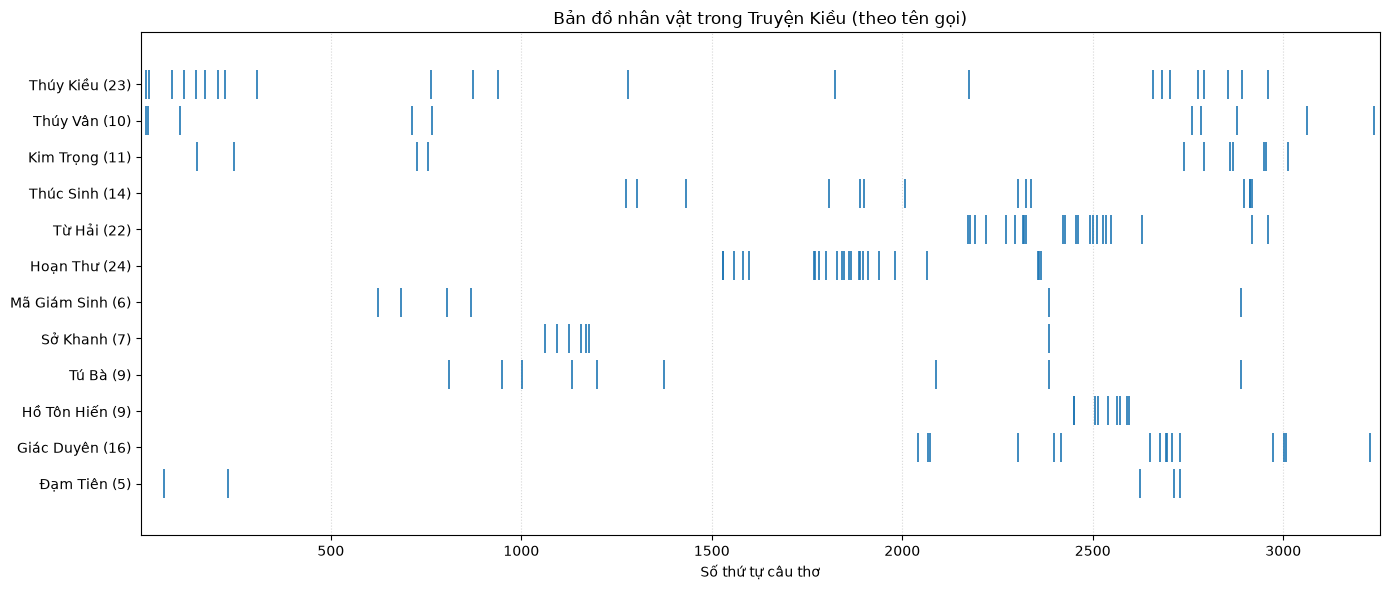

Thúy Kiều     :   23 câu, từ câu 16 đến câu 2961
Thúy Vân      :   10 câu, từ câu 16 đến câu 3237
Kim Trọng     :   11 câu, từ câu 148 đến câu 3012
Thúc Sinh     :   14 câu, từ câu 1276 đến câu 2917
Từ Hải        :   22 câu, từ câu 2172 đến câu 2960
Hoạn Thư      :   24 câu, từ câu 1529 đến câu 2363
Mã Giám Sinh  :    6 câu, từ câu 625 đến câu 2889
Sở Khanh      :    7 câu, từ câu 1062 đến câu 2384
Tú Bà         :    9 câu, từ câu 809 đến câu 2889
Hồ Tôn Hiến   :    9 câu, từ câu 2451 đến câu 2596
Giác Duyên    :   16 câu, từ câu 2040 đến câu 3228
Đạm Tiên      :    5 câu, từ câu 62 đến câu 2729


In [17]:
import re

import matplotlib.pyplot as plt

# Mỗi nhân vật: (các cách gọi, các cụm loại trừ - chứa cách gọi nhưng không chỉ nhân vật)
NHAN_VAT = {
    "Thúy Kiều":  (CACH_GOI_KIEU, LOAI_TRU_KIEU),
    "Thúy Vân":   (CACH_GOI_VAN, LOAI_TRU_VAN),
    "Kim Trọng":  (("kim trọng", "chàng kim", "kim lang", "kim"),
                   ("kim ngân", "kim môn", "kim mã", "kim thoa", "kim hoàn",
                    # "kim" là cây kim: "rụng cải rơi kim", "trôn kim", "mò kim", "duyên kim"
                    "rơi kim", "trôn kim", "mò kim", "duyên kim")),
    "Thúc Sinh":  (("thúc sinh", "chàng thúc", "thúc lang", "thúc"),
                   # "thúc phụ" (chú), "thúc ông" (cha Thúc Sinh), "thúc giáp" (giục binh)
                   ("thúc phụ", "thúc ông", "thúc giáp")),
    # "từ" là quan hệ từ/động từ rất phổ biến (từ khi, từ bi, tạ từ, ...) và "từ hải" không
    # xuất hiện liền nhau, nên chỉ nhận các cụm mà ngữ cảnh cho thấy rõ là Từ Hải
    "Từ Hải":     (("từ hải", "họ từ", "từ công", "từ rằng", "từ là đấng", "ngẫm từ",
                    "công từ mới", "thấy từ", "từ liền", "cơ từ"), ()),
    "Hoạn Thư":   (("hoạn thư", "hoạn bà", "tiểu thư", "hoạn"), ("hoạn nạn",)),
    "Mã Giám Sinh": (("mã giám sinh", "giám sinh", "mã"),
                     # "tư mã" (Tư Mã Tương Như), "kim mã" (cửa Kim Mã: chốn quan trường)
                     ("mã kiều", "tư mã", "kim mã")),
    "Sở Khanh":   (("sở khanh",), ()),
    "Tú Bà":      (("tú bà", "mụ tú"), ()),
    "Hồ Tôn Hiến": (("hồ tôn hiến", "tôn hiến", "tổng đốc", "hồ công", "hồ"),
                    # "hồ" trong từ thông thường: hồ cầm, giang hồ, hồ đồ, hồ nghi, ...
                    ("hồ cầm", "song hồ", "màu hồ", "trướng hồ", "giang hồ", "trì hồ",
                     "sơn hồ", "hồ đồ", "hồ nghi", "hồ điệp")),
    "Giác Duyên": (("giác duyên",), ()),
    "Đạm Tiên":   (("đạm tiên",), ()),
}


def vi_tri_xuat_hien(cau_tho: list, cach_goi: tuple, loai_tru: tuple = ()) -> list:
    """Trả về danh sách số thứ tự câu thơ (bắt đầu từ 1) có đề cập nhân vật."""
    mau_goi = re.compile(r"\b(" + "|".join(cach_goi) + r")\b")
    mau_loai = re.compile(r"\b(" + "|".join(loai_tru) + r")\b") if loai_tru else None
    vi_tri = []
    for stt, cau in enumerate(cau_tho, 1):
        c = mau_loai.sub("", cau) if mau_loai else cau
        if mau_goi.search(c):
            vi_tri.append(stt)
    return vi_tri


cau_tho = doc_cau_tho("TruyenKieu.txt")
ket_qua = {ten: vi_tri_xuat_hien(cau_tho, goi, loai) for ten, (goi, loai) in NHAN_VAT.items()}

# Vẽ biểu đồ: mỗi nhân vật một dòng, mỗi vạch là một câu thơ có đề cập
fig, ax = plt.subplots(figsize=(14, 6))
ten_nhan_vat = list(ket_qua)
ax.eventplot([ket_qua[t] for t in ten_nhan_vat],
             lineoffsets=range(len(ten_nhan_vat)), linelengths=0.8, linewidths=1.2)
ax.set_yticks(range(len(ten_nhan_vat)))
ax.set_yticklabels([f"{t} ({len(ket_qua[t])})" for t in ten_nhan_vat])
ax.invert_yaxis()
ax.set_xlim(1, len(cau_tho))
ax.set_xlabel("Số thứ tự câu thơ")
ax.set_title("Bản đồ nhân vật trong Truyện Kiều (theo tên gọi)")
ax.grid(axis="x", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

# In số câu đề cập của từng nhân vật và khoảng xuất hiện (câu đầu - câu cuối)
for ten, vt in ket_qua.items():
    print(f"{ten:14}: {len(vt):4} câu" + (f", từ câu {vt[0]} đến câu {vt[-1]}" if vt else ""))

**Thảo luận**
1. Biểu đồ cho biết gì về mạch truyện?
    - **Trả lời**: Dựa vào biểu đồ có thể biết thời điểm nhân vật bắt đầu xuất hiện và thời điểm cuối cùng (có thể biến mất hoặc chết) nhân vật được nhắc đến trong tác phẩm. Bên cạnh đó có thể biết được tầng suất xuất hiện của nhân vật, từ đó có thể cho rằng tuyến nhân vật này là nhân vật chính hoặc nhân vật phụ.
1. Kiểm tra: có nhân vật nào bị tìm sót hoặc tìm nhầm (ví dụ tên trùng với từ thông thường)? Bạn đã phát hiện và xử lý thế nào?
    - **Trả lời**: Ở version đầu khi code gen thì nhân vật Hồ Tôn Hiến không được đề cập đến trong danh sách. 
    Cách phát hiện: đem danh sách nhân vật và hỏi Google Gemini kiểm tra xem có nhân vật quan trọng nào chưa được nhắc đến và nhận được kết quả. => Yêu cầu AI sinh code cập nhật tuyến nhân vật.
    
    **Tìm nhầm:**
    1. Dựa vào biểu đồ xuất hiện của các nhân, có thể nhận xét rằng nhân vật Hồ Tôn Hiến đang bị đếm thiếu. Vì nhân vật này dẫn đến cái chết của Từ Hải nhưng lần xuất hiện cuối cùng của nhân vật này so với lần cuối xuất hiện của Từ Hải cách nhau khá xa. => Cách giải quyết: cập nhật lại (thêm) các cách gọi của nhân vật này để code có thể bắt được nhiều hơn. Kiếm chứng sau khi cập nhật cho thấy tần suất xuất hiện nhiều hơn version đầu.
    2. Vì từ `nàng` vẫn chưa được giải quyết, nên việc đếm thiếu các nhân vật nữ (như Kiều, Vân) là điều chắc chắn xảy ra. Và các nhân vật nam là `chàng`
1. Tự đánh giá: bạn hiểu được bao nhiêu phần code AI viết? Nếu cần sửa biểu đồ mà không có AI, bạn làm được không?
    - **Trả lời**: Em có thể hiểu được phần xử lý chuỗi, phần vẽ biểu đồ nếu bắt buộc phải cập nhật mà không dùng AI, em cũng có thể sẽ sửa được nhưng sẽ chậm hơn vì đọc tài liệu thay vì trực tiếp hỏi đáp và lấy gợi ý code từ AI.
    Về tổng quát: em có thể hiểu được 70-80% code do AI sinh ra

## Nhật ký AI

Có thể điền ngay bảng dưới đây, hoặc soạn trong tập tin Word/Markdown riêng (đặt tên `MSSV_NhatKyAI.docx` hoặc `MSSV_NhatKyAI.md`) và nộp kèm notebook. Trong tập tin riêng, bạn có thể dán ảnh chụp màn hình hoặc đường liên kết chia sẻ cuộc trò chuyện với AI thay cho việc chép lại prompt.

| Câu / Yêu cầu | Công cụ AI | Cấp độ đã dùng | Prompt chính (tóm tắt) | AI làm đúng / sai gì? | Bạn đã kiểm chứng thế nào? |
|---|---|---|---|---|---|
| Câu 1 | Google Gemini | cấp độ 1 và 4 | <br>-"Trong toán học, thuật toán Euclid trong tìm ước chung lớn nhất là gì ?"<br>-"Một doctest tiêu chuẩn phải viết ra sao ?"<br>-"Cách để chạy một doctest", "Các hàm có thể dùng với collections.Counter"<br>-"Có thể so sánh trực tiếp 2 dict trong python không"<br>-"Có thể so sánh 2 ký tự tiếng việt trong python không", "Hàm unicodedata.normalize sử dụng ra sao"<br>-"Sự khác nhau giữa NFC và NFD"<br>-"category trong unicodedata là gì"<br>-"Tại sao từ đ không được chuẩn hoá bởi unicodedata.normalize" | Gemini đưa ra giải thích và có các ví dụ cụ thể và đơn giản, vì không đưa ra bài toán cụ thể nên AI không mắc lỗi trong phần trả lời | <br>- Viết code test từng bước: Với bài tìm UCLN, viết ra nháp tìm ucln của các cặp số theo Euclid để hiểu đúng thuật toán và chuyển sang code. <br>- Với bài 12.10, thực hiện print kết quả ra và so sánh với Counter, tìm điểm sai và sửa lại code. <br>- Với bài 17.9: 1. Thử chuẩn hoá file content theo NFC/NFD rồi ghi trực tiếp ra file mới và kiểm tra kết quả để quyết định dùng NFC hay NFD, 2. Kiểm thử file không dấu và phát hiện ký tự đ chưa được chuyển đổi, tìm lý do và thử "thay thế toàn bộ đ bằng d" => Phát hiện ra str trong python là immutable nên đổi sang chiến thuật slice tạo chuỗi mới, sau đó phát hiện dòng cuối cùng trong file gốc không có kí tự "\n", phải cập nhật code lại bằng việc xuống dòng tương ứng với file gốc |
| Câu 2 | Claude Code (Claude Opus 5.5) trong VS Code | (a): hỏi chatbot biểu giá (xem phần a)<br>(b), (c): cấp độ 4 – nhờ AI rà soát, tự sửa đặc tả và kiểm thử<br>(d): cấp độ 6 – giao AI viết code từ đặc tả và kiểm thử<br>(d) điểm cộng: cấp độ 6 – giao AI viết hàm `tien_dien_nang_cao` cho nhiều hộ dùng chung công tơ | **(b)** "Bạn đánh giá thế nào về đặc tả hàm này" – 4 vòng<br>**(c)** Xin 1 ví dụ cách viết ca kiểm thử; "Review phần (c) kiểm thử có đủ chưa" – 6 vòng<br>**(d)** "Từ đặc tả (b) và kiểm thử (c) viết hàm `tien_dien` có docstring, doctest và hàm chạy kiểm thử; nếu sai không tự sửa kết quả, phải hỏi trước" – 1 vòng; sau đó 2 vòng cập nhật: `bang_gia` nhận list hoặc tuple, thêm 3 ca kiểm thử (TH14–16)<br>**(d) điểm cộng** "Tạo hàm mở rộng từ `tien_dien`, thêm `so_ho`; định mức mỗi bậc = định mức × số hộ, bậc cuối vẫn là None" – 1 vòng; sau đó 3 vòng sửa:<br>1. Chỉ cập nhật `bang_gia` theo số hộ rồi gọi `tien_dien`, không tự tính tiền<br>2. `so_ho` là số thực (vd. 10 người = 2.5 hộ), định mức mới làm tròn số học; kiểm tra `bang_gia` trước khi cập nhật<br>3. Tách phần kiểm tra `bang_gia` thành hàm `_bang_gia_hop_le` dùng chung cho cả 2 hàm | **Đúng:**<br>- Chỉ ra chỗ mơ hồ trong đặc tả: cấu trúc `bang_gia`, đơn vị `thue_gtgt`, làm tròn x.5, kiểm tra âm trước hay sau khi làm tròn, kiểu trả về<br>- Phát hiện kết quả tính tay sai ở các ca 7, 8, 9, 12, 13; các ca `BANG_GIA_FAIL` chứa nhiều lỗi cùng lúc nên che lấp nhau; ca 169.5 không phân biệt được làm tròn số học với `round()`<br>- Code đạt toàn bộ ca kiểm thử ngay lần đầu<br>**Sai / tự quyết ngoài đặc tả:**<br>- Ban đầu chỉ nhận `bang_gia` là list, tôi yêu cầu sửa để nhận cả tuple<br>- Tự quyết từ chối `bool`, `NaN`/`inf`, định mức kiểu float (vd. `50.0`)<br>- Đơn giá biểu giá cũ (QĐ 2941/QĐ-BCT) do AI gợi ý từ trí nhớ<br>**Điểm cộng – đúng:**<br>- Hàm mới đạt doctest và 29/29 ca cũ khi `so_ho = 1`<br>- Chỉ ra `tien_dien` chỉ nhận định mức nguyên nên 2.5 hộ (định mức 125.0) bị từ chối<br>- Nhân định mức × `so_ho` bằng `Decimal` để 62.5 không bị lưu thành 62.4999… (làm tròn sai thành 62)<br>**Điểm cộng – sai / tự quyết:**<br>- Lần đầu tự viết lại phần làm tròn và tính tiền thay vì gọi `tien_dien`, tôi yêu cầu sửa<br>- Lần thứ 2 chỉ cho `so_ho` là số nguyên, chưa hỗ trợ 2.5 hộ<br>- Bản đầu của `_bang_gia_hop_le` chép lại code kiểm tra trong `tien_dien`, tôi yêu cầu tách ra dùng chung | - Sửa lại kết quả tính tay theo góp ý và kiểm tra lại từng phép tính<br>- Chạy doctest (7 ví dụ) và 29 ca kiểm thử viết trước bằng `chay_kiem_thu`: đạt 29/29<br>- Đọc lại code: làm tròn dùng `Decimal` với `ROUND_HALF_UP` thay cho `round()` (vì `round(50.5) = 50`); kiểm tra âm trước khi làm tròn<br>- Cập nhật đặc tả (b) cho khớp với thay đổi list/tuple<br>**Điểm cộng:**<br>- Doctest `tien_dien_nang_cao` 10 ví dụ: 2 hộ, 2.5 hộ, 1.25 hộ (50 × 1.25 = 62.5 → 63), `so_ho` < 1, `so_ho` không phải số<br>- `chay_kiem_thu(tien_dien_nang_cao)`: đạt 29/29 (mặc định `so_ho = 1` cho kết quả giống `tien_dien`)<br>- Đọc lại code: hàm mới chỉ kiểm tra `so_ho`, `bang_gia`, tạo `bang_gia_theo_ho` rồi trả về kết quả của `tien_dien`<br>- AI chạy thêm bằng script ngoài notebook: 8 bảng `BANG_GIA_FAIL` với `so_ho = 2.5` đều trả về None; 2000 ca `so_ho` nguyên khớp với tự nhân bảng giá rồi gọi `tien_dien`; sau khi tách `_bang_gia_hop_le`, `tien_dien` cũ và mới cho kết quả giống nhau trên 20.000 bộ đầu vào ngẫu nhiên |
| Câu 3 - YC1 | **Phần 1:** Perplexity (câu 1), Google Gemini (câu 2–4)<br>**Phần 2:** Claude Code (Claude Opus 5.5) trong VS Code | **Phần 1:** hỏi thẳng chatbot, không đưa tập tin (theo yêu cầu đề)<br>**Phần 2:** cấp độ 4 – ra lệnh bằng lời, AI viết hàm, doctest và code kiểm chứng | **Phần 1:** hỏi nguyên văn 4 câu hỏi của đề<br>**Phần 2:** "Câu 3, Yêu cầu 1, dựa vào đầu dòng 2., viết hàm để trả lời các câu hỏi ở mục 'Trước khi làm'" – 1 vòng | **Phần 1 – đúng:** số câu thơ 3.254<br>**Phần 1 – sai:** `nàng` 179 lần (thực tế 200); từ nhiều nhất "thì" khoảng 400 lần (thực tế `thì` 109, nhiều nhất là `một` 321); thực từ nhiều nhất "hoa" 132 lần (thực tế `hoa` 136, đứng thứ 5 sau `người` 223)<br>**Phần 2 – đúng:**<br>- Viết 5 hàm `doc_cau_tho`, `so_cau_tho`, `dem_tu`, `tu_nhieu_nhat`, `thuc_tu_nhieu_nhat` theo kiểu Câu 1 (docstring + doctest)<br>- `dem_tu` so khớp nguyên tiếng, đếm được cả cụm nhiều tiếng (vd. `thúy kiều`)<br>- Nêu rõ "từ" = tiếng và hạn chế khi không tách từ ghép<br>**Phần 2 – tự quyết:**<br>- Danh sách hư từ `HU_TU`, đại từ `DAI_TU`, số từ `SO_TU` do AI tự lập theo phân loại từ loại, không lấy từ nguồn chuẩn<br>- Xếp `nàng`, `chàng` vào đại từ và `một` vào số từ nên bị loại khỏi thực từ; nếu tính `một` là thực từ thì kết quả câu 4 là `một`<br>- Tiếng đa loại (`ra`, `lại`, `cho`, `rằng`, ...) luôn bị xếp là hư từ vì không gán từ loại theo ngữ cảnh | - Chạy doctest của 5 hàm: không lỗi<br>- Số câu: kiểm tra câu lẻ 6 tiếng, câu chẵn 8 tiếng xen kẽ đủ 1627 cặp; so với số dòng của tập tin<br>- Số lần `nàng`: đếm lại bằng regex `nàng` trên toàn văn bản<br>- Tiếng và thực từ nhiều nhất: đối chiếu với hàm `yeu_vi` tự viết ở Câu 1 (Bài tập 12.10)<br>- In top 10 tiếng và top 10 thực từ để xem khoảng cách tần số và rà lại danh sách hư từ |
| Câu 3 - YC2 | Claude Code (Claude Opus 5.5) trong VS Code | Cấp độ 4 – ra lệnh bằng lời: AI viết hàm, doctest, code kiểm chứng, liệt kê cụm loại trừ và gợi ý nội dung thảo luận | 1. "Viết hàm đếm số câu thơ đề cập Thúy Kiều, tính khi xuất hiện 'Thúy Kiều', 'Kiều'; không chấp nhận viết thường 'kiều', 'thúy'" → AI báo tập tin toàn chữ thường, hỏi lại; tôi chọn cách không phân biệt hoa/thường và loại trừ theo ngữ cảnh<br>2. "Chỉ return 1 int, không tách 2 lần đếm cho 'kiều' và 'thúy kiều'; mỗi câu chỉ tính 1 lần"<br>3. "Áp dụng tương tự cho nhân vật Thúy Vân"<br>4. "'duyên vân', 'vân mồng' không phải đề cập Thúy Vân"<br>5. "Thảo luận lí do vì sao AI không hiểu được 'nàng' trong 1 câu thơ đang chỉ Kiều hay Vân" | **Đúng:**<br>- Phát hiện `TruyenKieu.txt` không có chữ hoa nào, nếu phân biệt hoa/thường thì kết quả là 0<br>- Liệt kê các cụm có chứa tên nhưng không chỉ nhân vật: `lam kiều`, `mã kiều`, `tiểu kiều`, `khóa xuân hai kiều`; `hành vân`, `vân vân`, `thanh vân`, `vân du`, `vân mồng`<br>- Hàm `so_cau_de_cap` dùng chung cho 2 nhân vật, mỗi câu chỉ đếm 1 lần: Thúy Kiều 23 câu, Thúy Vân 10 câu<br>- Thảo luận `nàng` có dẫn chứng từ tập tin: 196 câu có `nàng`, câu 68 (`nàng` = Đạm Tiên), câu 2878 (2 chữ `nàng` chỉ 2 người)<br>**Sai / tự quyết:**<br>- Bản đầu hàm trả về list và ô chạy gọi hàm 2 lần, tôi yêu cầu sửa thành trả về 1 số nguyên<br>- Tính câu 2840 `duyên vân` là đề cập Thúy Vân (11 câu), tôi yêu cầu loại → 10 câu<br>- Danh sách loại trừ do AI tự lập dựa vào ngữ cảnh và điển tích; AI tự nhận không chắc câu 2854 `tiếng kiều đồng vọng...` | - Chạy doctest của `so_cau_de_cap` (có ví dụ 1 câu có cả `thúy kiều` và `kiều` chỉ tính 1 lần)<br>- Kiểm chứng độc lập bằng regex: xóa cụm loại trừ rồi tìm cách gọi trên từng dòng, số câu khớp với hàm cho cả 2 nhân vật<br>- In danh sách câu tìm được và đọc lại từng câu; nhờ đó phát hiện câu 2840 `duyên vân` bị tính nhầm<br>- Đọc lại phần thảo luận `nàng`, sửa lại ý 2 theo cách hiểu của mình |
| Câu 3 - YC3 | Claude Code (Claude Opus 5.5) trong VS Code | **(1), (2):** cấp độ 4 – AI viết thân hàm `thanh_dieu`, `loi_luc_bat` và ô kiểm chứng trên Truyện Kiều; sau đó nhờ AI review `loi_luc_bat`<br>**(3):** nhờ AI sáng tác thơ; hàm `kiem_tra_bai_tho` tôi tự viết | **(1)** Nhờ AI hoàn thành 2 hàm `thanh_dieu`, `loi_luc_bat` theo docstring có sẵn<br>**(2)** Nhờ AI viết code ghép cặp lục bát, kiểm tra toàn bộ Truyện Kiều và in các cặp không đạt<br>**Review:** "Review hàm loi_luc_bat" – 1 vòng<br>**(3)** "Hãy sáng tác 8 câu (4 cặp) lục bát theo phong cách Truyện Kiều" – 1 vòng (đạt ngay, không cần gửi lỗi cho AI sửa) | **Đúng:**<br>- `thanh_dieu` dùng bảng nguyên âm có dấu, chuẩn hóa NFC; `loi_luc_bat` kiểm tra số tiếng, bằng trắc tiếng 2-4-6, tiếng 8 câu bát là bằng, tiếng 6/8 câu bát khác thanh<br>- Kết quả trên Truyện Kiều: 1598/1627 cặp đạt (98,2%); cả 29 lỗi đều ở câu lục, câu bát không có lỗi<br>- Giải thích 29 cặp không đạt: phần lớn là câu lục ngắt nhịp 3/3 có đối (`người quốc sắc / kẻ thiên tài`), 7 câu dạng `khi ... khi ...`<br>- Bài thơ "Tiễn biệt bên sông" đạt 4/4 cặp ngay vòng 1, vần cũng đúng (`cầu`–`sầu`, `đôi`–`trôi`–`hồi`, `theo`–`leo`–`chèo`, `xăm`–`năm`–`tằm`)<br>**Sai / thiếu (AI tự phát hiện khi review):**<br>- Ô hàm thiếu `import unicodedata`, chỉ chạy được nhờ ô Bài tập 17.9 đã import trước → tôi đã thêm<br>- Dấu câu đứng riêng (vd. `–`) bị đếm là một tiếng → tôi xử lý trong `kiem_tra_bai_tho` bằng cách bỏ dấu câu trước khi kiểm tra<br>- Doctest của `thanh_dieu` bị comment; `loi_luc_bat` chưa có ví dụ cho lỗi số tiếng và lỗi tiếng 6/8 cùng thanh<br>**Nhận xét:** AI chỉ tự nhẩm luật khi sáng tác, không chạy hàm kiểm tra; vì đạt ngay vòng 1 nên chưa thử được khả năng AI sửa lỗi theo phản hồi | - Chạy doctest của `loi_luc_bat`: đạt<br>- Chạy trên toàn bộ Truyện Kiều, đọc lại 29 cặp không đạt và đối chiếu với giải thích của AI<br>- Khi review, AI đối chiếu `thanh_dieu` với cách tách dấu bằng Unicode NFD trên 2383 tiếng khác nhau của Truyện Kiều: khớp 100%<br>- Tự viết `kiem_tra_bai_tho` (bỏ dấu câu, chữ thường, ghép cặp) để kiểm tra thơ AI: 4/4 cặp đạt |
| Câu 3 - YC4 | Claude Code (Claude Opus 5.5) trong VS Code: sinh code, rà lại và sửa<br>Google Gemini: rà danh sách nhân vật | Cấp độ 5 – vibe coding (theo đề cho phép): AI viết và sửa toàn bộ code vẽ biểu đồ bằng Matplotlib, tôi đọc kết quả và yêu cầu sửa | 1. Nhờ AI viết code vẽ biểu đồ vị trí (số thứ tự câu 1–3254) các nhân vật chính xuất hiện, dùng lại cách gọi và loại trừ của Thúy Kiều, Thúy Vân ở YC2<br>2. Hỏi Google Gemini: danh sách nhân vật đã đủ các nhân vật quan trọng chưa → thiếu Hồ Tôn Hiến<br>3. Yêu cầu AI cập nhật code, thêm Hồ Tôn Hiến<br>4. "Cập nhật nhật ký AI cho câu 3 - YC4" → Claude rà lại các câu tìm được, báo lỗi bắt nhầm/bắt sót<br>5. "Hãy sửa code phần biểu đồ nếu cần" – 1 vòng | **Đúng:**<br>- Code chạy được: mỗi nhân vật một dòng `eventplot`, nhãn có số câu, in khoảng xuất hiện (câu đầu – câu cuối)<br>- Dùng lại `CACH_GOI_KIEU`, `LOAI_TRU_KIEU`, `CACH_GOI_VAN`, `LOAI_TRU_VAN` nên kết quả Kiều 23, Vân 10 khớp YC2<br>- Các tên 2 tiếng ít trùng (`tú bà`, `sở khanh`, `đạm tiên`, `giác duyên`) tìm đúng ngay từ đầu<br>**Sai ở các bản trước (đã sửa ở vòng 5):**<br>- Bản đầu thiếu Hồ Tôn Hiến<br>- Cách gọi 1 tiếng bắt nhầm: `từ` (Từ Hải 54 câu, từ câu 171) bắt cả `kiều từ`, `từ đường`, `từ bi`, `tạ từ`, ...; `kim` bắt cả `rơi kim`, `trôn kim`, `mò kim`; `thúc` bắt cả `thúc phụ`, `thúc ông`, `thúc giáp`; `mã` bắt cả `tư mã`, `kim mã`<br>- Bắt sót Hồ Tôn Hiến (chỉ 2 câu) vì thiếu cách gọi `hồ công`, `hồ`<br>**Sau khi sửa:** Từ Hải 22 câu (2172–2960), Kim Trọng 11, Thúc Sinh 14 (từ câu 1276), Mã Giám Sinh 6, Hồ Tôn Hiến 9 (2451–2596)<br>**Tự quyết / hạn chế còn lại:**<br>- Từ Hải chỉ nhận các cụm có ngữ cảnh rõ (`họ từ`, `từ công`, `từ rằng`, `thấy từ`, ...) – danh sách lập theo các câu đã đọc, có thể sót cách gọi khác<br>- Không phân biệt được `sinh` (Kim Trọng hay Thúc Sinh), `chàng`, `nàng` nên các nhân vật vẫn bị đếm thiếu | - Hỏi Google Gemini để rà danh sách nhân vật quan trọng → phát hiện thiếu Hồ Tôn Hiến<br>- Đối chiếu biểu đồ với cốt truyện: lần xuất hiện cuối của Hồ Tôn Hiến cách xa lần cuối của Từ Hải → nghi bị đếm thiếu; sau khi sửa, Hồ Tôn Hiến xuất hiện đến câu 2596, cùng giai đoạn với cái chết của Từ Hải<br>- Nhận định `nàng`, `chàng` chưa xử lý được nên các nhân vật bị đếm thiếu (xem YC2)<br>- Nhờ Claude in danh sách câu tìm được của từng nhân vật để rà lại → phát hiện lỗi bắt nhầm/bắt sót; sau khi sửa, in lại và đọc từng câu của Từ Hải, Kim Trọng, Thúc Sinh, Mã Giám Sinh, Hồ Tôn Hiến: không còn câu bắt nhầm<br>- Chạy lại ô biểu đồ với `NHAN_VAT` mới |